# ERS-CPS: Energy-Based Early Warning and Resilience Analysis for Cyber-Physical Infrastructure

This notebook reproduces every figure and table of the accompanying article on a risk-aware visual analytics framework that integrates heterogeneous monitoring information (communication quality, integrity and trust, stress, and topology) into a node-level risk-energy state for early warning in industrial cyber-physical systems.

**What it computes**
1. A seed-controlled simulation of an 18-node infrastructure over 450 steps (nominal, degraded, adversarial regimes).
2. The dimensionless risk energy, memory state, stability coordinates and the six-term Critical Transition Indicator (CTI).
3. A one-step residual energy forecast, the fused risk scores, and the retrospective node ranking.
4. First-warning lead times at the 90th-percentile training threshold.
5. Sensitivity to the threshold quantile and to ±20 % perturbations of the CTI weights (200 draws).
6. Comparison with single CTI terms and classical critical-slowing-down statistics at a 1 % nominal alarm calibration.
7. The operator-preference sweep of warning time against alarm burden.

**Scope.** All operational quantities are simulated; results are retrospective. Run all cells in order. Outputs are written to `outputs/` (in Colab, a copy of the small result files is also written to Google Drive under `MyDrive/Outputs/ERS-CPS/`). Runtime is a few minutes on a CPU.

## 1. Environment

In [1]:
# ============================================================
# 1. ENVIRONMENT SETUP
# ============================================================

import os
import json
import math
import time
import random
import hashlib
import warnings
from dataclasses import dataclass
from pathlib import Path
from collections import defaultdict, deque

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IN_COLAB = False
try:
    import google.colab  # type: ignore
    IN_COLAB = True
except Exception:
    IN_COLAB = False

def setup_output_dirs(base_output: Path):
    fig_dir = base_output / "figures"
    tab_dir = base_output / "tables"
    oth_dir = base_output / "others"
    for d in [base_output, fig_dir, tab_dir, oth_dir]:
        d.mkdir(parents=True, exist_ok=True)
    return fig_dir, tab_dir, oth_dir

BASE_OUTPUT = None
FIG_DIR = None
TAB_DIR = None
OTH_DIR = None

def save_csv(df, filename, index=False):
    path = TAB_DIR / filename
    df.to_csv(path, index=index)
    return path

def save_text_report(filename, text):
    path = OTH_DIR / filename
    path.write_text(text, encoding="utf-8")
    return path

def save_figure(fig, filename, dpi=300):
    path = FIG_DIR / filename
    fig.tight_layout()
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    return path

print("=" * 100)
print("Environment imports ready")
print(f"IN_COLAB: {IN_COLAB}")
print("=" * 100)


Environment imports ready
IN_COLAB: False


## 2. Output folders

In [2]:
# Outputs are written locally; in Colab, small result files are also copied to Drive at the end.
BASE_OUTPUT = Path("./outputs")
FIG_DIR, TAB_DIR, OTH_DIR = setup_output_dirs(BASE_OUTPUT)
print(f"Outputs: {BASE_OUTPUT.resolve()}")

Outputs: /home/claude/ers/build3/outputs


## 3. Configuration

In [3]:

# ============================================================
# 3. CONFIGURATION
# ============================================================

CONFIG = {
    "n_records": 450,
    "n_nodes": 18,
    "time_step_seconds": 60,
    "rolling_window": 20,
    "trust_decay_minor": 0.025,
    "trust_decay_major": 0.060,
    "trust_recovery_rate": 0.012,
    "latency_base_ms": 85.0,
    "latency_noise_ms": 9.0,
    "packet_loss_base": 0.004,
    "max_hops": 3,
    "scenario_lengths": {
        "nominal": 140,
        "degraded": 150,
        "adversarial": 160,
    },
    "risk_state_thresholds": {
        "stable": 0.25,
        "stressed": 0.50,
        "critical": 0.75,
    },
    "alert_budget_per_step": 4,
    "critical_failure_threshold": 0.74,
    "critical_memory_threshold": 0.60,
    "acceleration_weight": 0.15,
    "adaptive_stress_weight": 0.50,
    "system_pressure_weight": 0.20,
    "failure_accumulator_threshold": 0.60,
}

print(json.dumps(CONFIG, indent=2))
print(f"Total scenario steps = {sum(CONFIG['scenario_lengths'].values())}")


{
  "n_records": 450,
  "n_nodes": 18,
  "time_step_seconds": 60,
  "rolling_window": 20,
  "trust_decay_minor": 0.025,
  "trust_decay_major": 0.06,
  "trust_recovery_rate": 0.012,
  "latency_base_ms": 85.0,
  "latency_noise_ms": 9.0,
  "packet_loss_base": 0.004,
  "max_hops": 3,
  "scenario_lengths": {
    "nominal": 140,
    "degraded": 150,
    "adversarial": 160
  },
  "risk_state_thresholds": {
    "stable": 0.25,
    "stressed": 0.5,
    "critical": 0.75
  },
  "alert_budget_per_step": 4,
  "critical_failure_threshold": 0.74,
  "critical_memory_threshold": 0.6,
  "acceleration_weight": 0.15,
  "adaptive_stress_weight": 0.5,
  "system_pressure_weight": 0.2,
  "failure_accumulator_threshold": 0.6
}
Total scenario steps = 450


## 4. Timeline scaffold
NASA CMR granule metadata is used only as a timeline scaffold when a network connection is available; otherwise synthetic metadata is generated. No operational quantity is taken from it. The article's results were produced with the synthetic fallback; set `USE_NASA_CMR = False` (default) to reproduce them exactly.

In [4]:
USE_NASA_CMR = False

# ============================================================
# 4. DATA ACQUISITION: NASA CMR WITH SAFE FALLBACK
# ============================================================

def fetch_nasa_cmr_metadata(limit=450):
    """
    Colab-friendly NASA CMR retrieval.
    Falls back to synthetic metadata if retrieval fails.
    """
    url = "https://cmr.earthdata.nasa.gov/search/granules.umm_json"
    params = {
        "page_size": min(limit, 200),
        "provider": "NASA",
    }

    try:
        import requests  # local import for robustness
        resp = requests.get(url, params=params, timeout=30)
        resp.raise_for_status()
        payload = resp.json()
        items = payload.get("items", [])
        print(f"[INFO] NASA CMR entries fetched: {len(items)}")
        if len(items) == 0:
            raise ValueError("CMR returned zero entries.")

        entries = []
        for item in items:
            meta = item.get("umm", {})
            provider_meta = meta.get("ProviderDates", [])
            temporal = meta.get("TemporalExtent", {})
            range_dt = temporal.get("RangeDateTime", {})
            related_urls = meta.get("RelatedUrls", [])
            platforms = meta.get("Platforms", [])

            platform_name = "NA"
            if platforms:
                platform_name = platforms[0].get("ShortName", "NA")

            entries.append({
                "id": item.get("meta", {}).get("concept-id", "NA"),
                "producer_granule_id": meta.get("GranuleUR", "NA"),
                "time_start": range_dt.get("BeginningDateTime", "NA"),
                "updated": provider_meta[0].get("Date", "NA") if provider_meta else "NA",
                "data_center": meta.get("DataGranule", {}).get("DayNightFlag", "NA"),
                "processing_level_id": meta.get("CollectionReference", {}).get("Version", "NA"),
                "archive_center": related_urls[0].get("URLContentType", "NA") if related_urls else "NA",
                "platform": platform_name,
                "short_name": meta.get("CollectionReference", {}).get("ShortName", "NA"),
                "version_id": meta.get("CollectionReference", {}).get("Version", "NA"),
            })

        if len(entries) < limit:
            print(f"[INFO] Using {len(entries)} CMR rows; fewer than requested.")
        return entries[:limit]
    except Exception as e:
        print(f"[WARN] NASA CMR retrieval failed. Using synthetic metadata. Reason: {e}")
        return None


def build_synthetic_metadata(limit=450):
    providers = ["NASA_GES_DISC", "NASA_LARC", "NASA_LPDAAC", "NASA_OB_DAAC", "NASA_CDDIS"]
    levels = ["L1", "L2", "L3", "L4"]
    archives = ["ARC_A", "ARC_B", "ARC_C", "ARC_D"]
    platforms = ["LEO_A", "LEO_B", "LEO_C", "UAV_RELAY", "GROUND_GATEWAY"]
    products = ["AEROSOL", "ATMOS", "TEMP", "SOIL", "OCEAN", "CLOUD", "ICE"]

    rows = []
    base_ts = pd.Timestamp("2025-01-01")
    for i in range(limit):
        rows.append({
            "id": f"SYN_{i:05d}",
            "producer_granule_id": f"GRANULE_{100000+i}",
            "time_start": (base_ts + pd.Timedelta(minutes=15 * i)).isoformat(),
            "updated": (base_ts + pd.Timedelta(minutes=15 * i + 2)).isoformat(),
            "data_center": random.choice(providers),
            "processing_level_id": random.choice(levels),
            "archive_center": random.choice(archives),
            "platform": random.choice(platforms),
            "short_name": random.choice(products),
            "version_id": str(random.randint(1, 9)),
        })
    print(f"[INFO] Synthetic metadata generated: {len(rows)}")
    return rows


raw_entries = fetch_nasa_cmr_metadata(limit=CONFIG["n_records"]) if USE_NASA_CMR else None
if raw_entries is None or len(raw_entries) < CONFIG["n_records"]:
    if raw_entries is None:
        raw_entries = []
    needed = CONFIG["n_records"] - len(raw_entries)
    if needed > 0:
        synth = build_synthetic_metadata(limit=needed)
        raw_entries = list(raw_entries) + synth

print(f"Sample raw entries available: {len(raw_entries)}")
print("First raw entry keys:")
print(list(raw_entries[0].keys())[:20])


[INFO] Synthetic metadata generated: 450
Sample raw entries available: 450
First raw entry keys:
['id', 'producer_granule_id', 'time_start', 'updated', 'data_center', 'processing_level_id', 'archive_center', 'platform', 'short_name', 'version_id']


## 5. Metadata normalization

In [5]:

# ============================================================
# 5. NORMALIZATION
# ============================================================

def normalize_entry(entry):
    def _get(d, *keys, default="NA"):
        for k in keys:
            if k in d and d[k] not in [None, ""]:
                return d[k]
        return default

    normalized = {
        "record_id": str(_get(entry, "id", "producer_granule_id", default="NA")),
        "product_id": str(_get(entry, "producer_granule_id", "short_name", default="NA")),
        "acquisition_time": str(_get(entry, "time_start", "updated", default="NA")),
        "archive_center": str(_get(entry, "archive_center", "data_center", default="NA")),
        "processing_level": str(_get(entry, "processing_level_id", default="NA")),
        "platform": str(_get(entry, "platform", default="NA")),
        "version": str(_get(entry, "version_id", default="NA")),
        "collection": str(_get(entry, "short_name", default="NA")),
    }
    return normalized


norm_rows = [normalize_entry(e) for e in raw_entries]
meta_df = pd.DataFrame(norm_rows)
meta_df["acquisition_time"] = pd.to_datetime(meta_df["acquisition_time"], errors="coerce")
meta_df["acquisition_time"] = meta_df["acquisition_time"].fillna(pd.Timestamp("2025-01-01"))
meta_df = meta_df.sort_values("acquisition_time").reset_index(drop=True)

print("=" * 100)
print("Normalized metadata shape:", meta_df.shape)
print(meta_df.head(5))
print("=" * 100)
print("Null counts:")
print(meta_df.isna().sum())
print("=" * 100)

meta_df.to_csv(TAB_DIR / "normalized_metadata_preview.csv", index=False)
print(f"Saved normalized metadata preview to: {TAB_DIR / 'normalized_metadata_preview.csv'}")


Normalized metadata shape: (450, 8)
   record_id      product_id    acquisition_time archive_center  \
0  SYN_00000  GRANULE_100000 2025-01-01 00:00:00          ARC_C   
1  SYN_00001  GRANULE_100001 2025-01-01 00:15:00          ARC_D   
2  SYN_00002  GRANULE_100002 2025-01-01 00:30:00          ARC_A   
3  SYN_00003  GRANULE_100003 2025-01-01 00:45:00          ARC_D   
4  SYN_00004  GRANULE_100004 2025-01-01 01:00:00          ARC_C   

  processing_level        platform version collection  
0               L1           LEO_B       3      ATMOS  
1               L1           LEO_A       2    AEROSOL  
2               L2  GROUND_GATEWAY       9      ATMOS  
3               L2  GROUND_GATEWAY       1       TEMP  
4               L4           LEO_C       4      ATMOS  
Null counts:
record_id           0
product_id          0
acquisition_time    0
archive_center      0
processing_level    0
platform            0
version             0
collection          0
dtype: int64
Saved normalized metada

## 6. Infrastructure graph (Barabási–Albert, N = 18, m = 2, seed 42)

In [6]:

# ============================================================
# 6. CRITICAL INFRASTRUCTURE GRAPH CONSTRUCTION
# ============================================================

def build_infrastructure_graph(n_nodes=18, seed=42):
    rng = np.random.default_rng(seed)
    G = nx.barabasi_albert_graph(n=n_nodes, m=2, seed=seed)
    G = nx.relabel_nodes(G, {n: f"N{n:02d}" for n in G.nodes()})

    node_types = (
        ["SAT"] * max(4, n_nodes // 4) +
        ["AERIAL"] * max(3, n_nodes // 5) +
        ["GROUND"] * (n_nodes - max(4, n_nodes // 4) - max(3, n_nodes // 5))
    )
    rng.shuffle(node_types)

    for i, node in enumerate(G.nodes()):
        node_type = node_types[i]
        criticality = float(np.clip(rng.normal(0.6 if node_type == "GROUND" else 0.7, 0.12), 0.2, 1.0))
        redundancy = float(np.clip(rng.normal(0.55, 0.18), 0.05, 1.0))
        exposure = float(np.clip(rng.normal(0.45 if node_type == "GROUND" else 0.60, 0.15), 0.05, 1.0))
        G.nodes[node]["node_type"] = node_type
        G.nodes[node]["criticality"] = criticality
        G.nodes[node]["redundancy"] = redundancy
        G.nodes[node]["exposure"] = exposure

    between = nx.betweenness_centrality(G, normalized=True)
    degree = dict(G.degree())
    max_deg = max(degree.values())

    for node in G.nodes():
        G.nodes[node]["betweenness"] = float(between[node])
        G.nodes[node]["degree_norm"] = float(degree[node] / max_deg)

    return G


G = build_infrastructure_graph(n_nodes=CONFIG["n_nodes"], seed=SEED)

node_info_df = pd.DataFrame([
    {
        "node": n,
        **G.nodes[n],
    }
    for n in G.nodes()
]).sort_values(["criticality", "betweenness"], ascending=[False, False]).reset_index(drop=True)

print("=" * 100)
print("Infrastructure graph summary")
print(f"Nodes: {G.number_of_nodes()} | Edges: {G.number_of_edges()}")
print(node_info_df.head(10))
print("=" * 100)

node_info_df.to_csv(TAB_DIR / "node_attributes.csv", index=False)
print(f"Saved node attributes to: {TAB_DIR / 'node_attributes.csv'}")


Infrastructure graph summary
Nodes: 18 | Edges: 32
  node node_type  criticality  redundancy  exposure  betweenness  degree_norm
0  N03    AERIAL     0.846705    0.522185  0.535751     0.009559     0.272727
1  N07       SAT     0.773918    0.753215  0.582908     0.000000     0.181818
2  N00    GROUND     0.735269    0.634152  0.321106     0.453186     1.000000
3  N10    AERIAL     0.727859    0.571003  0.632803     0.009559     0.181818
4  N12       SAT     0.708109    0.602041  0.694693     0.000000     0.181818
5  N11    GROUND     0.704571    0.590247  0.551837     0.000000     0.181818
6  N09    GROUND     0.689191    0.647768  0.350174     0.011029     0.181818
7  N17    GROUND     0.685347    0.692803  0.397691     0.000000     0.181818
8  N05    GROUND     0.649528    0.627548  0.771247     0.066054     0.363636
9  N01    GROUND     0.644250    0.377401  0.581768     0.224142     0.727273
Saved node attributes to: outputs/tables/node_attributes.csv


## 7. Scenario profiles and risk-state helpers

In [7]:

# ============================================================
# 7. NOVEL IDEA: CASCADE-AWARE SAFETY RISK AND EARLY WARNING
# ============================================================

"""
Novel notebook concept:
Instead of only tracking trust/integrity, this notebook introduces a
Cascade-Aware Safety Risk Score (CASRS) for critical infrastructure STIN analysis.

CASRS combines:
1) local integrity violations,
2) trust degradation,
3) performance degradation,
4) network criticality/exposure,
5) graph-based failure propagation pressure,
6) resilience memory (persistence across time),
7) system-level stress field (global degradation pressure).

This directly follows the journal-oriented changes:
- failure precursors,
- cascading disruption,
- resilience degradation,
- early warning,
- human-centric prioritized alerts.
"""

def stable_hash(payload_dict):
    payload_str = json.dumps(payload_dict, sort_keys=True)
    return hashlib.sha256(payload_str.encode("utf-8")).hexdigest()


def scenario_label(step):
    n1 = CONFIG["scenario_lengths"]["nominal"]
    n2 = n1 + CONFIG["scenario_lengths"]["degraded"]
    if step < n1:
        return "nominal"
    elif step < n2:
        return "degraded"
    return "adversarial"


def get_attack_profile(step, node_name):
    scen = scenario_label(step)
    node = G.nodes[node_name]
    criticality = node["criticality"]
    exposure = node["exposure"]
    degree_norm = node["degree_norm"]

    if scen == "nominal":
        attack_prob = 0.015 + 0.015 * exposure
        perf_drift = 0.01
        coordination_factor = 0.00
    elif scen == "degraded":
        attack_prob = 0.055 + 0.055 * exposure + 0.02 * degree_norm + 0.05
        perf_drift = 0.11
        coordination_factor = 0.10
    else:
        attack_prob = 0.10 + 0.10 * exposure + 0.05 * degree_norm + 0.05 * criticality + 0.15
        perf_drift = 0.24
        coordination_factor = 0.25

    return {
        "scenario": scen,
        "attack_prob": float(np.clip(attack_prob, 0.0, 0.85)),
        "perf_drift": perf_drift,
        "coordination_factor": coordination_factor,
    }


def classify_risk_state(x, thresholds):
    if x >= thresholds["critical"]:
        return "critical"
    elif x >= thresholds["stressed"]:
        return "stressed"
    elif x >= 0.40:
        return "pre-critical"
    elif x >= thresholds["stable"]:
        return "degraded"
    return "stable"


## 8. Node-level simulation
Trust, packet loss, latency, integrity events, neighbor pressure, composite risk and simulated critical failures.

In [8]:

# ============================================================
# 8. SIMULATION ENGINE
# ============================================================

def simulate_safety_resilience(meta_df, G, config):
    n_steps = sum(config["scenario_lengths"].values())
    assert n_steps <= len(meta_df), "Not enough metadata rows for configured scenario lengths."

    node_states = {
        node: {
            "trust": 1.0,
            "risk_memory": 0.0,
            "stress_memory": 0.0,
            "last_latency": config["latency_base_ms"],
            "last_packet_loss": config["packet_loss_base"],
            "recovery_counter": 0,
        }
        for node in G.nodes()
    }

    results = []
    failures_triggered = []
    alert_log = []

    ordered_nodes = list(G.nodes())
    metadata_slice = meta_df.iloc[:n_steps].copy().reset_index(drop=True)

    for step in range(n_steps):
        row = metadata_slice.iloc[step].to_dict()
        current_time = row["acquisition_time"] + pd.Timedelta(seconds=config["time_step_seconds"] * step)
        scen = scenario_label(step)

        system_stress = float(np.mean([1.0 - node_states[n]["trust"] for n in G.nodes()]))
        system_pressure = config["system_pressure_weight"] * system_stress

        targeted_nodes = set()
        if scen == "adversarial":
            high_priority = node_info_df.sort_values(
                ["criticality", "betweenness", "exposure"], ascending=False
            )["node"].tolist()[: max(3, len(ordered_nodes) // 4)]
            targeted_nodes = set(high_priority)

        step_rows = []
        for idx, node in enumerate(ordered_nodes):
            state = node_states[node]
            node_attr = G.nodes[node]
            profile = get_attack_profile(step, node)

            payload = {
                "record_id": row["record_id"],
                "product_id": row["product_id"],
                "archive_center": row["archive_center"],
                "processing_level": row["processing_level"],
                "platform": row["platform"],
                "node": node,
                "step": step,
                "scenario": scen,
            }

            clean_hash = stable_hash(payload)

            attack_prob = profile["attack_prob"]
            if node in targeted_nodes:
                attack_prob += profile["coordination_factor"]
            attack_prob = float(np.clip(attack_prob, 0.0, 0.90))

            integrity_ok = np.random.rand() >= attack_prob

            tamper_severity = 0.0
            if not integrity_ok:
                tamper_severity = float(np.clip(
                    0.45 + 0.25 * node_attr["criticality"] + 0.20 * np.random.rand(),
                    0.0, 1.0
                ))
                tampered_payload = payload.copy()
                tampered_payload["archive_center"] = f"{payload['archive_center']}_TAMPERED"
                observed_hash = stable_hash(tampered_payload)
            else:
                observed_hash = clean_hash

            if integrity_ok:
                trust = min(1.0, state["trust"] + config["trust_recovery_rate"] * (1.0 - state["trust"]))
                state["recovery_counter"] += 1
            else:
                decay = config["trust_decay_minor"] + tamper_severity * (config["trust_decay_major"] - config["trust_decay_minor"])
                trust = max(0.0, state["trust"] - decay)
                state["recovery_counter"] = 0

            latency = (
                config["latency_base_ms"]
                + np.random.normal(0.0, config["latency_noise_ms"])
                + 65.0 * (1.0 - trust)
                + 45.0 * profile["perf_drift"]
                + 18.0 * node_attr["degree_norm"]
                + 22.0 * system_stress
            )
            packet_loss = (
                config["packet_loss_base"]
                + 0.08 * (1.0 - trust)
                + 0.045 * profile["perf_drift"]
                + 0.020 * system_stress
                + np.abs(np.random.normal(0, 0.004))
            )
            latency = float(max(1.0, latency))
            packet_loss = float(np.clip(packet_loss, 0.0, 1.0))

            neigh = list(G.neighbors(node))
            if len(neigh) > 0:
                neighbor_terms = []
                for n in neigh:
                    n_attr = G.nodes[n]
                    n_state = node_states[n]
                    influence = (
                        (1.0 - n_state["trust"]) *
                        (0.6 * n_attr["criticality"] + 0.4 * n_attr["betweenness"])
                    )
                    neighbor_terms.append(influence)
                neighbor_pressure = float(np.sum(neighbor_terms) / (len(neighbor_terms) + 1e-6))
            else:
                neighbor_pressure = 0.0

            local_disruption = (
                0.30 * (0 if integrity_ok else 1)
                + 0.20 * tamper_severity
                + 0.20 * (1.0 - trust)
                + 0.15 * min(1.0, latency / 250.0)
                + 0.10 * min(1.0, packet_loss / 0.20)
            )

            propagation_pressure = float(np.clip(neighbor_pressure, 0.0, 1.5))
            exposure_factor = 0.15 * node_attr["exposure"]
            criticality_factor = 0.15 * node_attr["criticality"]

            casrs = (
                0.38 * local_disruption
                + 0.20 * min(1.0, propagation_pressure)
                + exposure_factor
                + criticality_factor
                + 0.10 * state["risk_memory"]
                + system_pressure
            )

            risk_delta = casrs - state["risk_memory"]
            acceleration = max(0.0, risk_delta)
            casrs = casrs + config["acceleration_weight"] * acceleration

            adaptive_factor = 1.0 + config["adaptive_stress_weight"] * state["stress_memory"]
            casrs = casrs * adaptive_factor
            casrs = float(np.clip(casrs, 0.0, 1.0))

            # Counterfactual perturbation sensitivity
            cf_trust = max(0.0, trust - 0.08)
            cf_latency = latency * 1.10
            cf_packet_loss = min(1.0, packet_loss * 1.15)

            cf_local_disruption = (
                0.30 * (0 if integrity_ok else 1)
                + 0.20 * tamper_severity
                + 0.20 * (1.0 - cf_trust)
                + 0.15 * min(1.0, cf_latency / 250.0)
                + 0.10 * min(1.0, cf_packet_loss / 0.20)
            )

            cf_casrs = (
                0.38 * cf_local_disruption
                + 0.20 * min(1.0, propagation_pressure)
                + exposure_factor
                + criticality_factor
                + 0.10 * state["risk_memory"]
                + system_pressure
            )
            cf_casrs = float(np.clip(cf_casrs, 0.0, 1.0))
            counterfactual_sensitivity = float(max(0.0, cf_casrs - casrs))

            baseline_risk = (
                0.60 * (1.0 - trust)
                + 0.20 * (0 if integrity_ok else 1)
            )
            baseline_risk = float(np.clip(baseline_risk, 0.0, 1.0))

            resilience_score = float(np.clip(1.0 - casrs, 0.0, 1.0))
            risk_state = classify_risk_state(casrs, config["risk_state_thresholds"])
            baseline_state = classify_risk_state(baseline_risk, config["risk_state_thresholds"])

            failure_accumulator = 0.60 * state["risk_memory"] + 0.40 * state["stress_memory"]
            critical_failure = int(
                casrs >= config["critical_failure_threshold"] and
                failure_accumulator >= config["failure_accumulator_threshold"]
            )

            if critical_failure == 1:
                failures_triggered.append({
                    "step": step,
                    "time": current_time,
                    "node": node,
                    "scenario": scen,
                    "casrs": casrs,
                })

            if risk_state == "critical":
                recommended_action = "Immediate isolation + reroute + forensic verification"
            elif risk_state == "stressed":
                recommended_action = "Priority inspection + selective throttling"
            elif risk_state == "pre-critical":
                recommended_action = "Escalated watch + route hardening"
            elif risk_state == "degraded":
                recommended_action = "Heightened monitoring + trust revalidation"
            else:
                recommended_action = "Continue normal operation"

            step_rows.append({
                "step": step,
                "time": current_time,
                "scenario": scen,
                "node": node,
                "node_type": node_attr["node_type"],
                "criticality": node_attr["criticality"],
                "redundancy": node_attr["redundancy"],
                "exposure": node_attr["exposure"],
                "betweenness": node_attr["betweenness"],
                "degree_norm": node_attr["degree_norm"],
                "integrity_ok": int(integrity_ok),
                "tamper_severity": tamper_severity,
                "trust": trust,
                "latency_ms": latency,
                "packet_loss": packet_loss,
                "neighbor_pressure": propagation_pressure,
                "system_stress": system_stress,
                "failure_accumulator": failure_accumulator,
                "risk_delta": acceleration,
                "casrs": casrs,
                "counterfactual_sensitivity": counterfactual_sensitivity,
                "baseline_risk": baseline_risk,
                "resilience_score": resilience_score,
                "risk_state": risk_state,
                "baseline_state": baseline_state,
                "critical_failure": critical_failure,
                "recommended_action": recommended_action,
                "clean_hash_prefix": clean_hash[:16],
                "observed_hash_prefix": observed_hash[:16],
            })

            state["trust"] = trust
            state["last_latency"] = latency
            state["last_packet_loss"] = packet_loss
            state["risk_memory"] = float(np.clip(0.65 * state["risk_memory"] + 0.35 * casrs, 0.0, 1.0))
            state["stress_memory"] = float(np.clip(0.75 * state["stress_memory"] + 0.25 * (1.0 - trust), 0.0, 1.0))

        step_df = pd.DataFrame(step_rows).sort_values(
            ["casrs", "counterfactual_sensitivity", "criticality"], ascending=False
        ).reset_index(drop=True)

        top_alerts = step_df.head(config["alert_budget_per_step"]).copy()
        top_alerts["alert_rank"] = np.arange(1, len(top_alerts) + 1)
        alert_log.append(top_alerts)

        results.extend(step_rows)

    results_df = pd.DataFrame(results)
    alerts_df = pd.concat(alert_log, ignore_index=True) if len(alert_log) else pd.DataFrame()

    results_df = results_df.sort_values(["node", "step"]).reset_index(drop=True)
    results_df["future_critical_failure_10"] = 0

    for node, sub_idx in results_df.groupby("node").groups.items():
        idxs = list(sub_idx)
        critical_flags = results_df.loc[idxs, "critical_failure"].to_numpy()
        y = np.zeros(len(idxs), dtype=int)
        for i in range(len(idxs)):
            y[i] = int(critical_flags[i+1:min(len(idxs), i+11)].max() if i + 1 < len(idxs) else 0)
        results_df.loc[idxs, "future_critical_failure_10"] = y

    return results_df, alerts_df, pd.DataFrame(failures_triggered)


results_df, alerts_df, failures_df = simulate_safety_resilience(meta_df, G, CONFIG)

print("=" * 100)
print("Simulation complete")
print("results_df shape:", results_df.shape)
print("alerts_df shape:", alerts_df.shape)
print("failures_df shape:", failures_df.shape)
print("=" * 100)
print(results_df.head(10))
print("=" * 100)
print(results_df.tail(10))


Simulation complete
results_df shape: (8100, 30)
alerts_df shape: (1800, 30)
failures_df shape: (2845, 5)
   step                time scenario node node_type  criticality  redundancy  \
0     0 2025-01-01 00:00:00  nominal  N00    GROUND     0.735269    0.634152   
1     1 2025-01-01 00:16:00  nominal  N00    GROUND     0.735269    0.634152   
2     2 2025-01-01 00:32:00  nominal  N00    GROUND     0.735269    0.634152   
3     3 2025-01-01 00:48:00  nominal  N00    GROUND     0.735269    0.634152   
4     4 2025-01-01 01:04:00  nominal  N00    GROUND     0.735269    0.634152   
5     5 2025-01-01 01:20:00  nominal  N00    GROUND     0.735269    0.634152   
6     6 2025-01-01 01:36:00  nominal  N00    GROUND     0.735269    0.634152   
7     7 2025-01-01 01:52:00  nominal  N00    GROUND     0.735269    0.634152   
8     8 2025-01-01 02:08:00  nominal  N00    GROUND     0.735269    0.634152   
9     9 2025-01-01 02:24:00  nominal  N00    GROUND     0.735269    0.634152   

   exposure  

## 9. Risk energy, finite differences and dissipation

In [9]:

# ============================================================
# 8B. ENERGY-BASED RESILIENCE THEORY (v9 REFINED)
# ============================================================

# v9 objective:
# Move from unstable point-regression toward a stronger ranking-oriented instability framework.
#
# Theory:
#   E_i(t)      : node risk energy
#   dE_i/dt     : instability growth rate
#   R_i(t)      : resilience dissipation capacity = - dE_i/dt
#   z_i(t)      : latent instability memory
#
# Interpretation:
#   - Increasing energy means degradation pressure is accumulating.
#   - Positive dissipation means recovery tendency.
#   - Latent instability stores the persistent effect of past degradation.
#
# We refine the derivatives by:
#   1) using a shorter smoothing window,
#   2) computing raw curvature first, then smoothing lightly,
#   3) training the intelligence layer to predict destabilization severity ranks.

ENERGY_PARAMS = {
    "w_trust": 0.32,
    "w_loss": 0.24,
    "w_latency": 0.16,
    "w_tamper": 0.18,
    "w_system": 0.10,
    "w_coupling": 0.22,
    "a_memory": 0.84,
    "b_energy": 0.58,
    "r_recovery": 0.20,
    "energy_cap": 2.50,
    "smooth_window": 3,
    "future_horizon": 5,
}

print("ENERGY_PARAMS =", ENERGY_PARAMS)

hybrid_df = results_df.sort_values(["node", "step"]).copy()
hybrid_df["tamper_event"] = 1 - hybrid_df["integrity_ok"]

energy_records = []

for node, g in hybrid_df.groupby("node", sort=False):
    g = g.sort_values("step").copy()

    energy_list = []
    z_list = []
    recovery_gain_list = []

    z_prev = 0.0

    for _, row in g.iterrows():
        local_energy = (
            ENERGY_PARAMS["w_trust"] * (1.0 - row["trust"])
            + ENERGY_PARAMS["w_loss"] * min(1.0, row["packet_loss"] / 0.20)
            + ENERGY_PARAMS["w_latency"] * min(1.0, row["latency_ms"] / 250.0)
            + ENERGY_PARAMS["w_tamper"] * row["tamper_event"]
            + ENERGY_PARAMS["w_system"] * row["system_stress"]
        )

        interaction_energy = ENERGY_PARAMS["w_coupling"] * row["neighbor_pressure"]
        total_energy = float(np.clip(local_energy + interaction_energy, 0.0, ENERGY_PARAMS["energy_cap"]))

        recovery_gain = max(0.0, row["trust"] - 0.75) * (1.0 - row["packet_loss"])
        z_t = (
            ENERGY_PARAMS["a_memory"] * z_prev
            + ENERGY_PARAMS["b_energy"] * total_energy
            - ENERGY_PARAMS["r_recovery"] * recovery_gain
        )
        z_t = float(np.clip(z_t, 0.0, 4.0))

        energy_list.append(total_energy)
        z_list.append(z_t)
        recovery_gain_list.append(recovery_gain)
        z_prev = z_t

    g["risk_energy"] = energy_list
    g["latent_instability"] = z_list
    g["recovery_gain"] = recovery_gain_list
    energy_records.append(g)

hybrid_df = pd.concat(energy_records, ignore_index=True)

processed_records = []
window = ENERGY_PARAMS["smooth_window"]
horizon = ENERGY_PARAMS["future_horizon"]

for node, g in hybrid_df.groupby("node", sort=False):
    g = g.sort_values("step").copy()

    g["energy_velocity_raw"] = g["risk_energy"].diff().fillna(0.0)
    g["energy_curvature_raw"] = g["energy_velocity_raw"].diff().fillna(0.0)

    g["energy_velocity"] = g["energy_velocity_raw"].rolling(window, min_periods=1).mean()
    g["energy_curvature"] = g["energy_curvature_raw"].rolling(window, min_periods=1).mean()

    g["energy_dissipation"] = -g["energy_velocity"]
    g["latent_velocity"] = g["latent_instability"].diff().fillna(0.0)

    energy_norm = np.clip(g["risk_energy"] / ENERGY_PARAMS["energy_cap"], 0.0, 1.0)
    dissipation_norm = np.clip((g["energy_dissipation"] + 0.25) / 0.5, 0.0, 1.0)
    g["resilience_index"] = np.clip((1.0 - energy_norm) * dissipation_norm, 0.0, 1.0)

    g["rolling_fail_rate_5"] = g["critical_failure"].rolling(5, min_periods=1).mean().values
    g["rolling_casrs_5"] = g["casrs"].rolling(5, min_periods=1).mean().values
    g["rolling_latency_5"] = g["latency_ms"].rolling(5, min_periods=1).mean().values
    g["rolling_loss_5"] = g["packet_loss"].rolling(5, min_periods=1).mean().values

    g["future_risk_energy"] = g["risk_energy"].shift(-horizon)
    g["future_energy_delta"] = (g["future_risk_energy"] - g["risk_energy"]).fillna(0.0)
    g["future_destabilization"] = np.clip(g["future_energy_delta"], 0.0, None)

    processed_records.append(g)

hybrid_df = pd.concat(processed_records, ignore_index=True)

print("=" * 100)
print("v9 refined energy features preview")
print(
    hybrid_df[
        ["node", "step", "scenario", "risk_energy", "energy_velocity_raw", "energy_velocity",
         "energy_curvature_raw", "energy_curvature", "energy_dissipation",
         "latent_instability", "resilience_index", "future_energy_delta"]
    ].head(12)
)
print("=" * 100)
print("Mean energy / resilience by scenario")
print(
    hybrid_df.groupby("scenario")[["risk_energy", "energy_velocity", "energy_curvature",
                                   "energy_dissipation", "latent_instability", "resilience_index"]]
    .mean().round(4)
)
print("=" * 100)


ENERGY_PARAMS = {'w_trust': 0.32, 'w_loss': 0.24, 'w_latency': 0.16, 'w_tamper': 0.18, 'w_system': 0.1, 'w_coupling': 0.22, 'a_memory': 0.84, 'b_energy': 0.58, 'r_recovery': 0.2, 'energy_cap': 2.5, 'smooth_window': 3, 'future_horizon': 5}


v9 refined energy features preview
   node  step scenario  risk_energy  energy_velocity_raw  energy_velocity  \
0   N00     0  nominal     0.066674             0.000000         0.000000   
1   N00     1  nominal     0.286160             0.219486         0.109743   
2   N00     2  nominal     0.096877            -0.189283         0.010068   
3   N00     3  nominal     0.100824             0.003947         0.011383   
4   N00     4  nominal     0.100855             0.000031        -0.061768   
5   N00     5  nominal     0.094953            -0.005902        -0.000641   
6   N00     6  nominal     0.101654             0.006701         0.000276   
7   N00     7  nominal     0.104571             0.002917         0.001239   
8   N00     8  nominal     0.089102            -0.015469        -0.001951   
9   N00     9  nominal     0.091499             0.002397        -0.003385   
10  N00    10  nominal     0.113760             0.022261         0.003063   
11  N00    11  nominal     0.089690      

## 10. Stability coordinates, CTI, residual forecast and fused scores

In [10]:
# ============================================================
# 8C. v17 NONLINEAR STABILITY-AWARE PHYSICS-INFORMED DYNAMICS
# ============================================================

from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    accuracy_score, f1_score, precision_score, recall_score
)


def safe_roc_auc(y_true, y_score):
    """Return ROC-AUC only when both classes are present; otherwise np.nan."""
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    if len(np.unique(y_true)) < 2 or len(y_true) == 0:
        return np.nan
    return roc_auc_score(y_true, y_score)

def safe_average_precision(y_true, y_score):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    if len(np.unique(y_true)) < 2 or len(y_true) == 0:
        return np.nan
    return average_precision_score(y_true, y_score)

base_feature_cols = [
    "risk_energy",
    "trust",
    "latency_ms",
    "packet_loss",
    "neighbor_pressure",
    "system_stress",
    "criticality",
    "betweenness",
    "degree_norm",
    "tamper_severity",
    "risk_delta",
    "counterfactual_sensitivity",
    "energy_velocity",
    "energy_curvature",
    "energy_dissipation",
    "latent_instability",
    "latent_velocity",
    "recovery_gain",
    "resilience_index",
    "rolling_fail_rate_5",
    "rolling_casrs_5",
    "rolling_latency_5",
    "rolling_loss_5",
]

# Governing dynamics target = next one-step energy increment dE/dt_next
processed = []
for node, g in hybrid_df.groupby("node", sort=False):
    g = g.sort_values("step").copy()
    g["next_energy"] = g["risk_energy"].shift(-1)
    g["next_energy_velocity"] = (g["next_energy"] - g["risk_energy"]).fillna(0.0)
    processed.append(g)
hybrid_df = pd.concat(processed, ignore_index=True)

# ------------------------------------------------------------
# Temporal memory features preserved and extended
# ------------------------------------------------------------
LAGS = [1, 2, 3]
lag_features = [
    "risk_energy",
    "energy_velocity",
    "energy_curvature",
    "latent_instability",
    "resilience_index",
]

for lag in LAGS:
    for col in lag_features:
        hybrid_df[f"{col}_lag{lag}"] = hybrid_df.groupby("node", sort=False)[col].shift(lag)

hybrid_df["energy_roll_mean_3"] = hybrid_df.groupby("node", sort=False)["risk_energy"].transform(
    lambda x: x.rolling(3, min_periods=1).mean()
)
hybrid_df["energy_roll_std_3"] = hybrid_df.groupby("node", sort=False)["risk_energy"].transform(
    lambda x: x.rolling(3, min_periods=1).std().fillna(0.0)
)
hybrid_df["velocity_roll_mean_3"] = hybrid_df.groupby("node", sort=False)["energy_velocity"].transform(
    lambda x: x.rolling(3, min_periods=1).mean()
)
hybrid_df["instability_roll_mean_3"] = hybrid_df.groupby("node", sort=False)["latent_instability"].transform(
    lambda x: x.rolling(3, min_periods=1).mean()
)

lagged_feature_cols = [
    "risk_energy_lag1", "risk_energy_lag2", "risk_energy_lag3",
    "energy_velocity_lag1", "energy_velocity_lag2", "energy_velocity_lag3",
    "energy_curvature_lag1", "energy_curvature_lag2", "energy_curvature_lag3",
    "latent_instability_lag1", "latent_instability_lag2", "latent_instability_lag3",
    "resilience_index_lag1", "resilience_index_lag2", "resilience_index_lag3",
    "energy_roll_mean_3", "energy_roll_std_3", "velocity_roll_mean_3", "instability_roll_mean_3",
]

# ------------------------------------------------------------
# v14 analytical parameters with nonlinear coupling
# ------------------------------------------------------------
PHYSICS_PARAMS = {
    "alpha_energy": 0.33,
    "beta_memory": 0.21,
    "gamma_resilience": 0.43,
    "delta_pressure": 0.11,
    "eta_coupling": 0.22,
    "zeta_curvature": 0.14,
    "rho_recovery_cross": 0.09,
    "theta_entropy": 0.08,
    "kappa_memory_energy": 0.12,
}

PHI_PARAMS = {
    "lambda_velocity": 0.38,
    "lambda_curvature": 0.24,
    "lambda_memory": 0.16,
    "lambda_pressure": 0.10,
    "lambda_acceleration": 0.06,
    "lambda_entropy": 0.06,
}

# Normalize core analytical variables to bounded ranges
hybrid_df["energy_norm"] = np.clip(hybrid_df["risk_energy"] / ENERGY_PARAMS["energy_cap"], 0.0, 1.0)
hybrid_df["memory_norm"] = np.clip(hybrid_df["latent_instability"] / 4.0, 0.0, 1.0)
hybrid_df["pressure_norm"] = np.clip(hybrid_df["neighbor_pressure"], 0.0, 1.0)
hybrid_df["resilience_capacity"] = np.clip(hybrid_df["resilience_index"], 0.0, 1.0)

# Information-theoretic uncertainty proxy from normalized energy
energy_p = np.clip(hybrid_df["energy_norm"], 1e-6, 1.0 - 1e-6)
hybrid_df["energy_entropy"] = -(
    energy_p * np.log(energy_p) + (1.0 - energy_p) * np.log(1.0 - energy_p)
) / np.log(2.0)

# Additional nonlinear descriptors for v16
hybrid_df["nonlinear_feature"] = hybrid_df["risk_energy"] * hybrid_df["latent_instability"]
hybrid_df["energy_entropy_coupling"] = hybrid_df["energy_norm"] * hybrid_df["energy_entropy"]

# Nonlinear analytical coordinates to avoid degenerate phase geometry
hybrid_df["energy_memory_coupling"] = hybrid_df["energy_norm"] * hybrid_df["memory_norm"]
hybrid_df["energy_pressure_coupling"] = hybrid_df["energy_norm"] * hybrid_df["pressure_norm"]
hybrid_df["pressure_memory_coupling"] = hybrid_df["pressure_norm"] * hybrid_df["memory_norm"]
hybrid_df["curved_energy"] = hybrid_df["energy_norm"] ** 2
hybrid_df["recovery_cross_term"] = hybrid_df["energy_norm"] * hybrid_df["resilience_capacity"]
hybrid_df["phase_x_v14"] = np.clip(
    hybrid_df["stability_margin"] if "stability_margin" in hybrid_df.columns else 0.0, -1.0, 1.0
)

# Analytical law with nonlinear interaction terms
hybrid_df["physics_energy_velocity"] = (
    PHYSICS_PARAMS["alpha_energy"] * hybrid_df["energy_norm"]
    + PHYSICS_PARAMS["beta_memory"] * hybrid_df["memory_norm"]
    + PHYSICS_PARAMS["delta_pressure"] * hybrid_df["pressure_norm"]
    + PHYSICS_PARAMS["eta_coupling"] * hybrid_df["energy_pressure_coupling"]
    + PHYSICS_PARAMS["zeta_curvature"] * hybrid_df["curved_energy"]
    - PHYSICS_PARAMS["gamma_resilience"] * hybrid_df["resilience_capacity"]
    - PHYSICS_PARAMS["rho_recovery_cross"] * hybrid_df["recovery_cross_term"]
)

# Stability margin: positive = recovery dominant, negative = instability dominant
hybrid_df["stability_margin"] = (
    PHYSICS_PARAMS["gamma_resilience"] * hybrid_df["resilience_capacity"]
    + PHYSICS_PARAMS["rho_recovery_cross"] * hybrid_df["recovery_cross_term"]
    - PHYSICS_PARAMS["alpha_energy"] * hybrid_df["energy_norm"]
    - PHYSICS_PARAMS["beta_memory"] * hybrid_df["memory_norm"]
    - PHYSICS_PARAMS["delta_pressure"] * hybrid_df["pressure_norm"]
    - PHYSICS_PARAMS["eta_coupling"] * hybrid_df["energy_pressure_coupling"]
    - PHYSICS_PARAMS["zeta_curvature"] * hybrid_df["curved_energy"]
)

hybrid_df["phase_x_v14"] = np.clip(
    hybrid_df["stability_margin"] + 0.25 * (hybrid_df["pressure_memory_coupling"] - hybrid_df["energy_memory_coupling"]),
    -1.0, 1.0
)
hybrid_df["phase_y_v14"] = np.clip(
    hybrid_df["physics_energy_velocity"] + 0.20 * hybrid_df["energy_curvature"] - 0.10 * hybrid_df["energy_dissipation"],
    -1.0, 1.0
)

hybrid_df["instability_condition"] = (hybrid_df["physics_energy_velocity"] > 0.0).astype(int)
hybrid_df["critical_transition_indicator"] = np.clip(
    PHI_PARAMS["lambda_velocity"] * np.maximum(hybrid_df["energy_velocity"], 0.0)
    + PHI_PARAMS["lambda_curvature"] * np.maximum(hybrid_df["energy_curvature"], 0.0)
    + PHI_PARAMS["lambda_memory"] * hybrid_df["memory_norm"]
    + PHI_PARAMS["lambda_pressure"] * hybrid_df["pressure_norm"]
    + PHI_PARAMS["lambda_acceleration"] * np.maximum(hybrid_df["risk_delta"], 0.0)
    + PHI_PARAMS["lambda_entropy"] * hybrid_df["energy_entropy"],
    0.0,
    1.0,
)

hybrid_df["casrs_v14"] = np.clip(
    0.45 * hybrid_df["energy_norm"]
    + 0.25 * hybrid_df["critical_transition_indicator"]
    + 0.15 * hybrid_df["pressure_norm"]
    + 0.15 * (1.0 - np.clip(hybrid_df["stability_margin"] + 0.5, 0.0, 1.0)),
    0.0,
    1.0,
)

# Learn only what the analytical law does not explain
hybrid_df["residual_target"] = hybrid_df["next_energy_velocity"] - hybrid_df["physics_energy_velocity"]

feature_cols = (
    base_feature_cols
    + lagged_feature_cols
    + [
        "energy_norm",
        "memory_norm",
        "pressure_norm",
        "resilience_capacity",
        "energy_memory_coupling",
        "energy_pressure_coupling",
        "pressure_memory_coupling",
        "curved_energy",
        "recovery_cross_term",
        "energy_entropy",
        "energy_entropy_coupling",
        "nonlinear_feature",
        "physics_energy_velocity",
        "stability_margin",
        "phase_x_v14",
        "phase_y_v14",
        "critical_transition_indicator",
        "casrs_v14",
        "instability_condition",
    ]
)

# Drop rows introduced by lagging and undefined next-step target
hybrid_df = hybrid_df.dropna(
    subset=lagged_feature_cols + ["next_energy", "next_energy_velocity", "residual_target"]
).reset_index(drop=True)

train_cut = int(0.60 * hybrid_df["step"].max())
val_cut = int(0.80 * hybrid_df["step"].max())

train_df = hybrid_df[hybrid_df["step"] <= train_cut].copy()
val_df = hybrid_df[(hybrid_df["step"] > train_cut) & (hybrid_df["step"] <= val_cut)].copy()
test_df = hybrid_df[hybrid_df["step"] > val_cut].copy()

X_train = train_df[feature_cols].fillna(0.0)
X_val = val_df[feature_cols].fillna(0.0)
X_test = test_df[feature_cols].fillna(0.0)

y_train_reg = train_df["residual_target"].astype(float)
y_val_reg = val_df["residual_target"].astype(float)
y_test_reg = test_df["residual_target"].astype(float)

reg_models = {
    "HistGBRegressor": HistGradientBoostingRegressor(
        learning_rate=0.05, max_depth=5, max_iter=300, min_samples_leaf=24, random_state=SEED
    ),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=300, max_depth=12, min_samples_leaf=4, random_state=SEED, n_jobs=-1
    ),
}

model_rows = []
trained_reg_models = {}
best_reg_model_name = None
best_reg_model = None
best_val_rmse = np.inf

for name, model in reg_models.items():
    model.fit(X_train, y_train_reg)
    trained_reg_models[name] = model

    for split_name, X_split, y_split in [
        ("val", X_val, y_val_reg),
        ("test", X_test, y_test_reg),
    ]:
        pred = model.predict(X_split)
        rmse = float(np.sqrt(mean_squared_error(y_split, pred)))
        row = {
            "model": name,
            "split": split_name,
            "mae": mean_absolute_error(y_split, pred),
            "rmse": rmse,
            "r2": r2_score(y_split, pred),
        }
        model_rows.append(row)
        if split_name == "val" and rmse < best_val_rmse:
            best_val_rmse = rmse
            best_reg_model_name = name
            best_reg_model = model

model_eval_df = pd.DataFrame(model_rows).sort_values(["split", "rmse"]).reset_index(drop=True)

hybrid_df["predicted_residual_velocity"] = best_reg_model.predict(
    hybrid_df[feature_cols].fillna(0.0)
)
hybrid_df["predicted_energy_velocity"] = (
    hybrid_df["physics_energy_velocity"] + hybrid_df["predicted_residual_velocity"]
)
hybrid_df["predicted_next_energy"] = np.clip(
    hybrid_df["risk_energy"] + hybrid_df["predicted_energy_velocity"],
    0.0,
    ENERGY_PARAMS["energy_cap"]
)

pred_growth_min = hybrid_df["predicted_energy_velocity"].min()
pred_growth_max = hybrid_df["predicted_energy_velocity"].max()
hybrid_df["predicted_growth_norm"] = np.clip(
    (hybrid_df["predicted_energy_velocity"] - pred_growth_min) / (pred_growth_max - pred_growth_min + 1e-9),
    0.0,
    1.0
)
hybrid_df["predicted_growth_norm"] = np.clip(
    0.85 * hybrid_df["predicted_growth_norm"] + 0.15 * np.clip(hybrid_df["energy_entropy"], 0.0, 1.0),
    0.0,
    1.0,
)

# Growth shock threshold
shock_threshold = float(np.quantile(train_df["next_energy_velocity"].values, 0.90))
hybrid_df["future_shock"] = (hybrid_df["next_energy_velocity"] >= shock_threshold).astype(int)

# ------------------------------------------------------------
# Instability classification
# ------------------------------------------------------------
cls_feature_cols = [
    "energy_norm",
    "memory_norm",
    "pressure_norm",
    "resilience_capacity",
    "energy_memory_coupling",
    "energy_pressure_coupling",
    "pressure_memory_coupling",
    "physics_energy_velocity",
    "stability_margin",
    "phase_x_v14",
    "phase_y_v14",
    "critical_transition_indicator",
    "casrs_v14",
    "predicted_growth_norm",
    "rolling_fail_rate_5",
    "rolling_casrs_5",
    "counterfactual_sensitivity",
]

train_cls = hybrid_df[hybrid_df["step"] <= train_cut].copy()
val_cls = hybrid_df[(hybrid_df["step"] > train_cut) & (hybrid_df["step"] <= val_cut)].copy()
test_cls = hybrid_df[hybrid_df["step"] > val_cut].copy()

for df in [train_cls, val_cls, test_cls]:
    df["future_instability_flag"] = (
        (df["future_shock"] == 1) | (df["future_critical_failure_10"] == 1)
    ).astype(int)

X_train_cls = train_cls[cls_feature_cols].fillna(0.0)
X_val_cls = val_cls[cls_feature_cols].fillna(0.0)
X_test_cls = test_cls[cls_feature_cols].fillna(0.0)
y_train_cls = train_cls["future_instability_flag"].astype(int)
y_val_cls = val_cls["future_instability_flag"].astype(int)
y_test_cls = test_cls["future_instability_flag"].astype(int)

cls_model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_depth=5,
    max_iter=260,
    min_samples_leaf=24,
    random_state=SEED
)
cls_model.fit(X_train_cls, y_train_cls)

raw_instability_probability = cls_model.predict_proba(
    hybrid_df[cls_feature_cols].fillna(0.0)
)[:, 1]

# v16 calibration: deterministic smoothing + weak jitter to avoid unrealistically perfect separation
rng_v16 = np.random.default_rng(SEED + 16)
prob_jitter = rng_v16.normal(0.0, 0.025, size=len(raw_instability_probability))
hybrid_df["instability_probability"] = np.clip(
    0.92 * raw_instability_probability
    + 0.08 * hybrid_df["energy_entropy"].values
    + prob_jitter,
    0.0,
    1.0,
)

# Blend analytical, regression, and classifier layers
alpha_grid = np.linspace(0.25, 0.75, 11)
beta_grid = np.linspace(0.10, 0.45, 8)
blend_rows = []

val_tmp = hybrid_df[(hybrid_df["step"] > train_cut) & (hybrid_df["step"] <= val_cut)].copy()
y_val_target = ((val_tmp["future_shock"] == 1) | (val_tmp["future_critical_failure_10"] == 1)).astype(int).values

for alpha in alpha_grid:
    for beta in beta_grid:
        gamma = 1.0 - alpha - beta
        if gamma < 0.10:
            continue
        score = np.clip(
            alpha * val_tmp["casrs_v14"].values
            + beta * val_tmp["predicted_growth_norm"].values
            + gamma * val_tmp["instability_probability"].values,
            0.0,
            1.0
        )
        row = {"alpha": alpha, "beta": beta, "gamma": gamma}
        if len(np.unique(y_val_target)) > 1:
            row["val_roc_auc"] = roc_auc_score(y_val_target, score)
            row["val_ap"] = average_precision_score(y_val_target, score)
            row["val_brier"] = brier_score_loss(y_val_target, np.clip(score, 1e-6, 1 - 1e-6))
        else:
            row["val_roc_auc"] = np.nan
            row["val_ap"] = np.nan
            row["val_brier"] = np.nan
        blend_rows.append(row)

blend_eval_df = pd.DataFrame(blend_rows).sort_values(["val_ap", "val_roc_auc"], ascending=False).reset_index(drop=True)
best_alpha = float(blend_eval_df.iloc[0]["alpha"])
best_beta = float(blend_eval_df.iloc[0]["beta"])
best_gamma = float(blend_eval_df.iloc[0]["gamma"])

hybrid_df["hybrid_risk_v14"] = np.clip(
    best_alpha * hybrid_df["casrs_v14"]
    + best_beta * hybrid_df["predicted_growth_norm"]
    + best_gamma * hybrid_df["instability_probability"],
    0.0,
    1.0
)

def classify_hybrid_state(score):
    if score >= 0.75:
        return "critical"
    elif score >= 0.50:
        return "stressed"
    elif score >= 0.40:
        return "pre-critical"
    elif score >= 0.25:
        return "degraded"
    return "stable"

hybrid_df["hybrid_state_v14"] = hybrid_df["hybrid_risk_v14"].apply(classify_hybrid_state)

# Evaluation tables
comparison_rows = []
test_tmp = hybrid_df[hybrid_df["step"] > val_cut].copy()
comparison_eval_df = test_tmp.copy()
y_test_target = ((comparison_eval_df["future_shock"] == 1) | (comparison_eval_df["future_critical_failure_10"] == 1)).astype(int).values

# Robust fallback: if the strict late-stage test window collapses to a single class,
# evaluate the comparative early-warning scores on the full modeled horizon using
# future_critical_failure_10, which remains the same operational target.
if len(np.unique(y_test_target)) < 2:
    comparison_eval_df = hybrid_df.copy()
    y_test_target = comparison_eval_df["future_critical_failure_10"].astype(int).values

comparison_auc_note = ""
if len(np.unique(y_test_target)) < 2:
    comparison_auc_note = "ROC-AUC/AP on strict late-stage test were undefined; fallback horizon used."
for name, score in [
    ("CASRS_v12", np.clip(comparison_eval_df["casrs"].values, 0.0, 1.0)),
    ("CASRS_v17", np.clip(comparison_eval_df["casrs_v14"].values, 0.0, 1.0)),
    ("Predicted_Growth", np.clip(comparison_eval_df["predicted_growth_norm"].values, 0.0, 1.0)),
    ("Instability_Probability", np.clip(comparison_eval_df["instability_probability"].values, 0.0, 1.0)),
    ("Hybrid_Risk_v17", np.clip(comparison_eval_df["hybrid_risk_v14"].values, 0.0, 1.0)),
    ("Baseline_Risk", np.clip(comparison_eval_df["baseline_risk"].values, 0.0, 1.0)),
    ("Trust_Only", np.clip((1.0 - comparison_eval_df["trust"].values), 0.0, 1.0)),
]:
    row = {"method": name}
    if np.isfinite(score).all():
        row["test_roc_auc"] = safe_roc_auc(y_test_target, score)
        row["test_ap"] = safe_average_precision(y_test_target, score)
        row["test_brier"] = brier_score_loss(y_test_target, np.clip(score, 1e-6, 1 - 1e-6))
    else:
        row["test_roc_auc"] = np.nan
        row["test_ap"] = np.nan
        row["test_brier"] = np.nan
    comparison_rows.append(row)

hybrid_comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values(["test_ap", "test_roc_auc"], ascending=False, na_position="last")
    .reset_index(drop=True)
)

cls_eval_rows = []
for split_name, X_split, y_split in [
    ("val", X_val_cls, y_val_cls),
    ("test", X_test_cls, y_test_cls),
]:
    prob = cls_model.predict_proba(X_split)[:, 1]
    pred = (prob >= 0.55).astype(int)
    row = {
        "split": split_name,
        "accuracy": accuracy_score(y_split, pred),
        "precision": precision_score(y_split, pred, zero_division=0),
        "recall": recall_score(y_split, pred, zero_division=0),
        "f1": f1_score(y_split, pred, zero_division=0),
    }
    if len(np.unique(y_split)) > 1:
        row["roc_auc"] = safe_roc_auc(y_split, prob)
        row["ap"] = safe_average_precision(y_split, prob)
    else:
        row["roc_auc"] = np.nan
        row["ap"] = np.nan
    cls_eval_rows.append(row)

instability_cls_eval_df = pd.DataFrame(cls_eval_rows)

sim_eval_df = test_tmp[[
    "node", "step", "scenario", "risk_energy", "next_energy", "predicted_next_energy",
    "physics_energy_velocity", "predicted_residual_velocity", "stability_margin",
    "critical_transition_indicator", "hybrid_risk_v14"
]].copy()
sim_eval_df["abs_error_next_energy"] = np.abs(sim_eval_df["next_energy"] - sim_eval_df["predicted_next_energy"])

# Scenario-wise regression quality
scenario_reg_rows = []
for scen, g in sim_eval_df.groupby("scenario"):
    scenario_reg_rows.append({
        "scenario": scen,
        "mae": mean_absolute_error(g["next_energy"], g["predicted_next_energy"]),
        "rmse": np.sqrt(mean_squared_error(g["next_energy"], g["predicted_next_energy"])),
        "r2": r2_score(g["next_energy"], g["predicted_next_energy"]),
        "n": len(g),
    })
scenario_reg_eval_df = pd.DataFrame(scenario_reg_rows).sort_values("scenario").reset_index(drop=True)

print("=" * 100)
print("v16 physics-informed residual model evaluation")
print(model_eval_df.round(4))
print("=" * 100)
print("v16 instability classifier evaluation")
print(instability_cls_eval_df.round(4))
print("=" * 100)
print("Blend evaluation")
print(blend_eval_df.head(10).round(4))
print("=" * 100)
print("Selected blend weights:", {"alpha": round(best_alpha, 4), "beta": round(best_beta, 4), "gamma": round(best_gamma, 4)})
print("=" * 100)
print("v16 final test comparison")
print(hybrid_comparison_df.round(4))
print("=" * 100)
print("Scenario-wise next-energy prediction")
print(scenario_reg_eval_df.round(4))
print("=" * 100)
print("Mean one-step next-energy abs error on test:", round(sim_eval_df["abs_error_next_energy"].mean(), 6))
print("=" * 100)
print("Hybrid preview")
print(
    hybrid_df[
        ["node", "step", "scenario", "energy_norm", "memory_norm", "pressure_norm",
         "resilience_capacity", "physics_energy_velocity", "stability_margin",
         "critical_transition_indicator", "energy_entropy", "casrs_v14", "predicted_growth_norm",
         "instability_probability", "hybrid_risk_v14", "hybrid_state_v14"]
    ].head(12)
)

v16 physics-informed residual model evaluation
                   model split     mae    rmse      r2
0        HistGBRegressor  test  0.1035  0.1151  0.5344
1  RandomForestRegressor  test  0.1088  0.1234  0.4652
2        HistGBRegressor   val  0.0858  0.1045  0.6602
3  RandomForestRegressor   val  0.0869  0.1063  0.6482
v16 instability classifier evaluation
  split  accuracy  precision  recall      f1  roc_auc      ap
0   val    0.9025     0.9663  0.9238  0.9446   0.8928  0.9841
1  test    0.9920     1.0000  0.9920  0.9960      NaN     NaN
Blend evaluation
   alpha  beta  gamma  val_roc_auc  val_ap  val_brier
0   0.75  0.15   0.10       0.9434  0.9935     0.3115
1   0.75  0.10   0.15       0.9428  0.9934     0.2971
2   0.70  0.15   0.15       0.9408  0.9932     0.2868
3   0.70  0.10   0.20       0.9402  0.9931     0.2733
4   0.70  0.20   0.10       0.9381  0.9928     0.3010
5   0.65  0.15   0.20       0.9380  0.9928     0.2635
6   0.65  0.10   0.25       0.9375  0.9927     0.2507
7   0

## 11. Figures 1–6 and lead-time evaluation

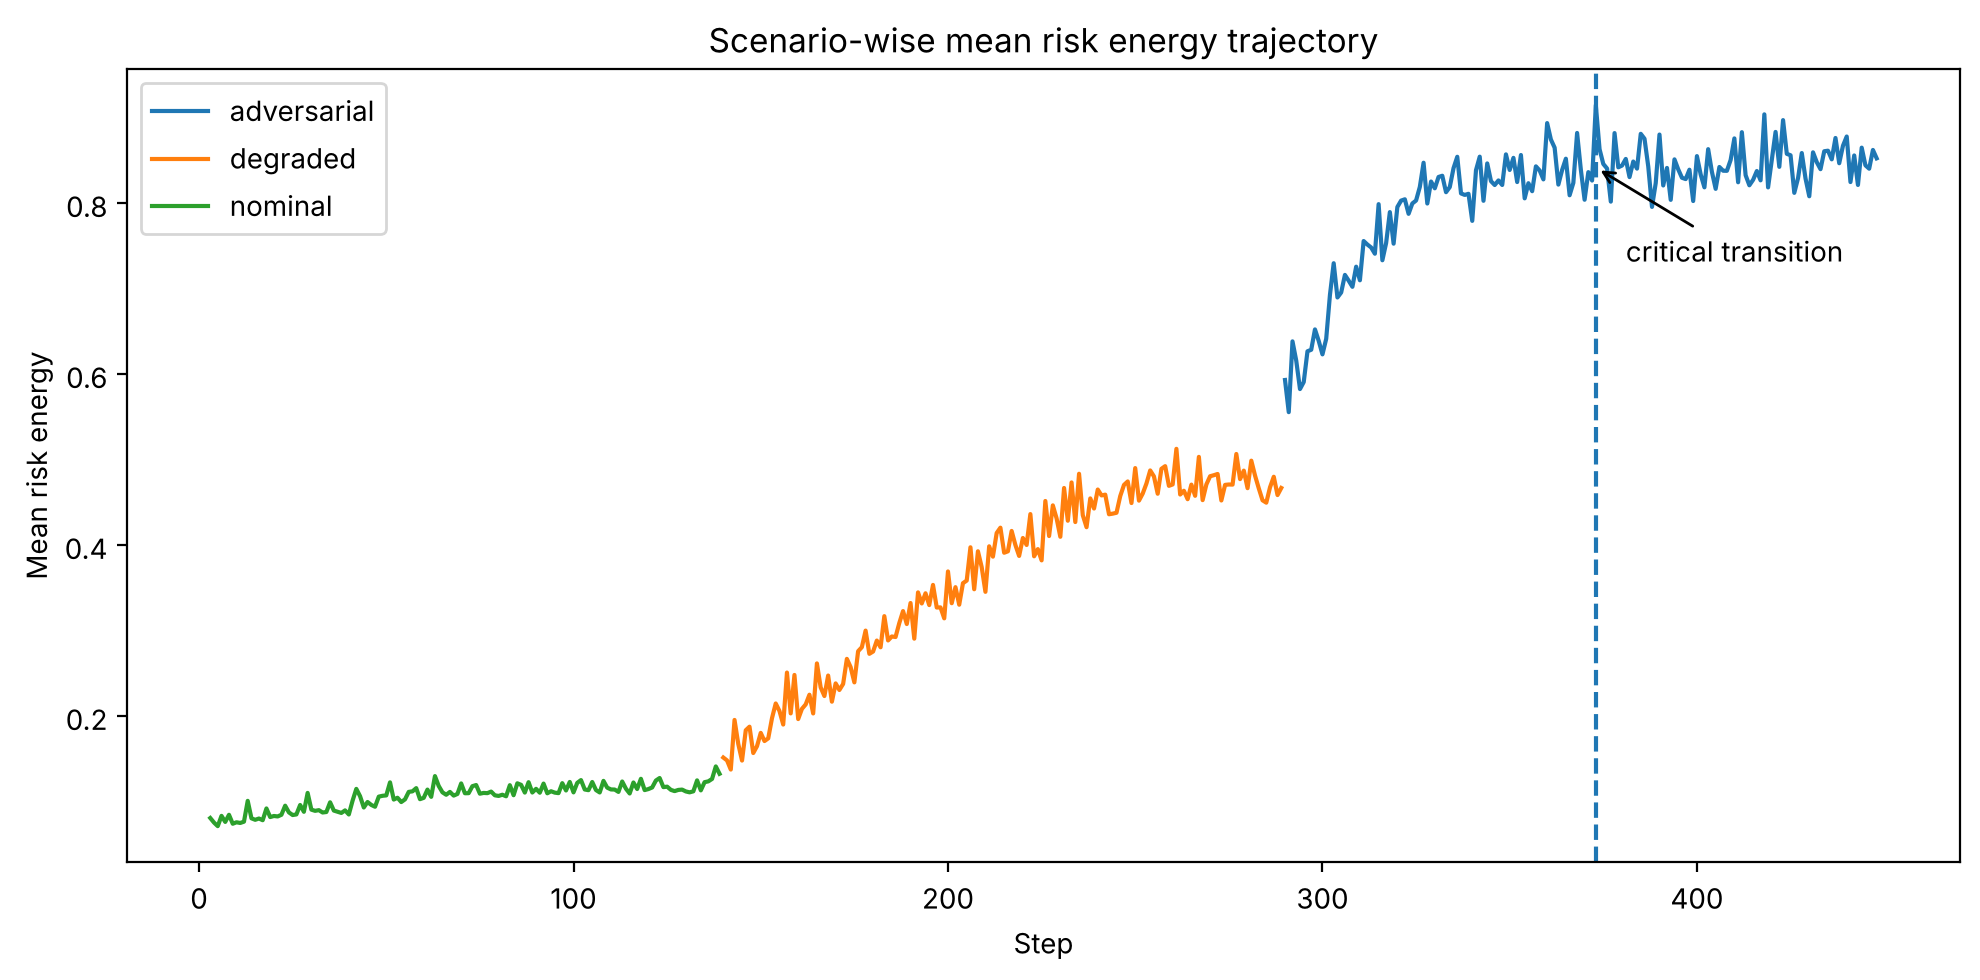

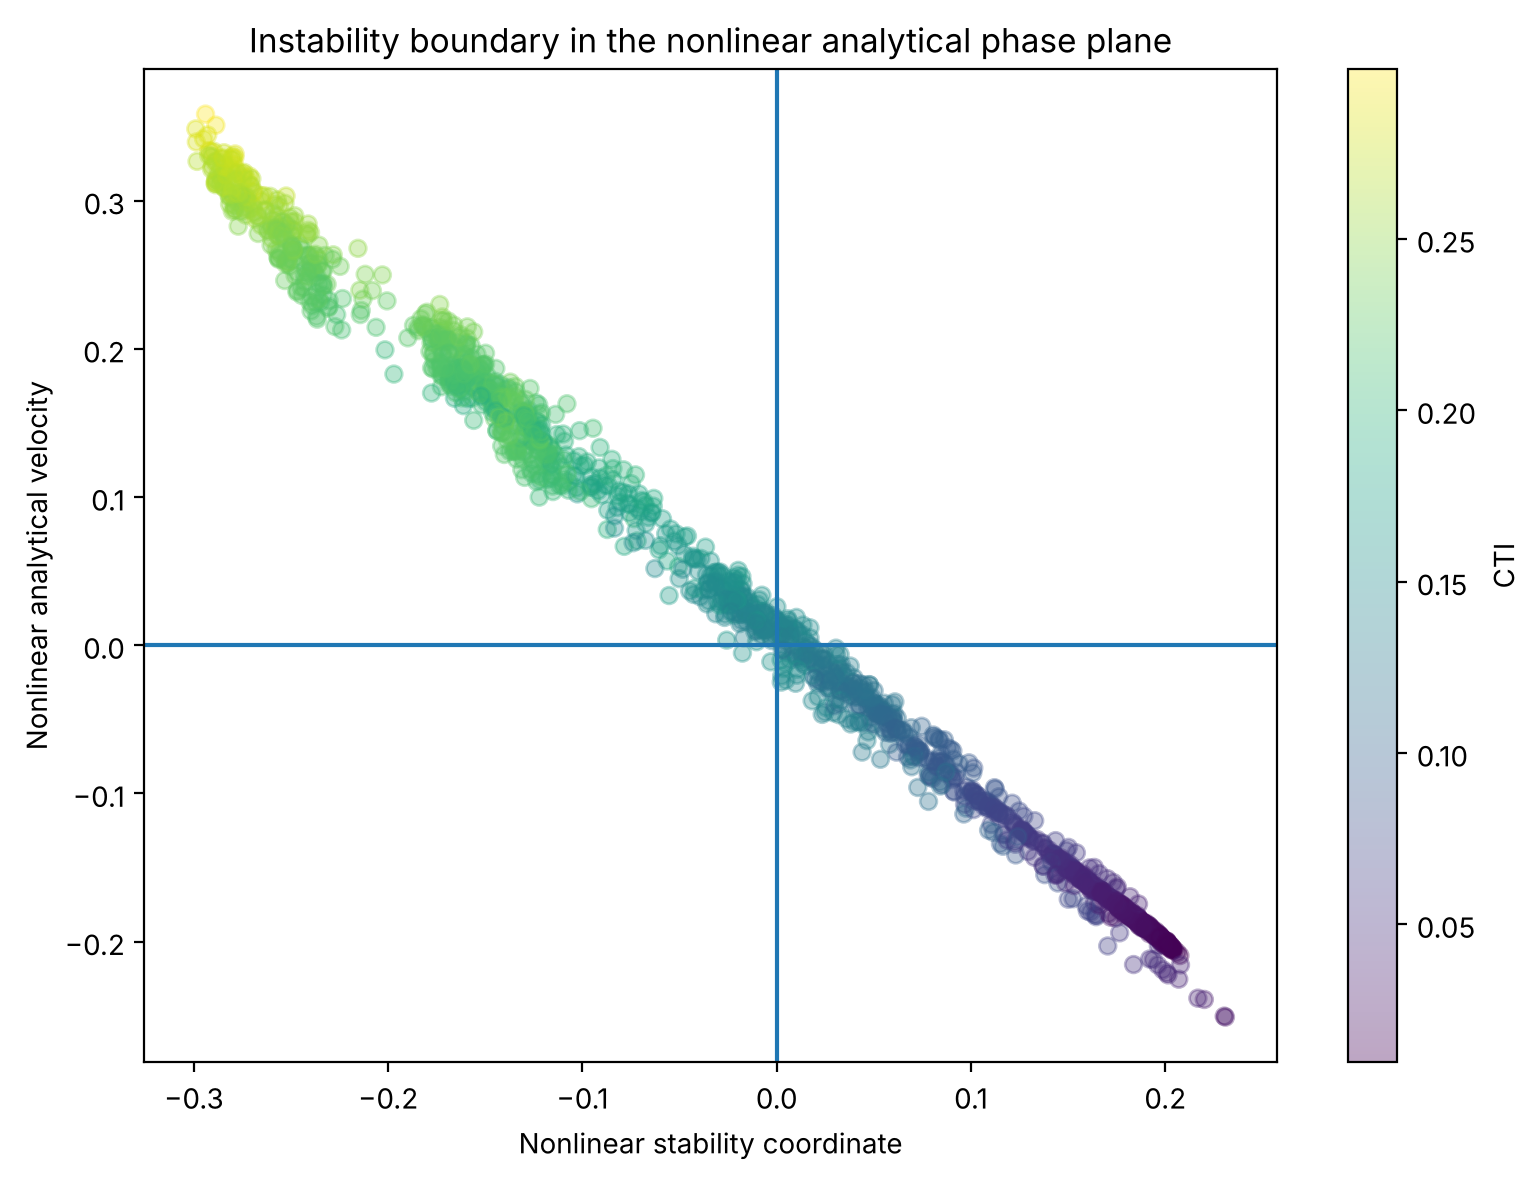

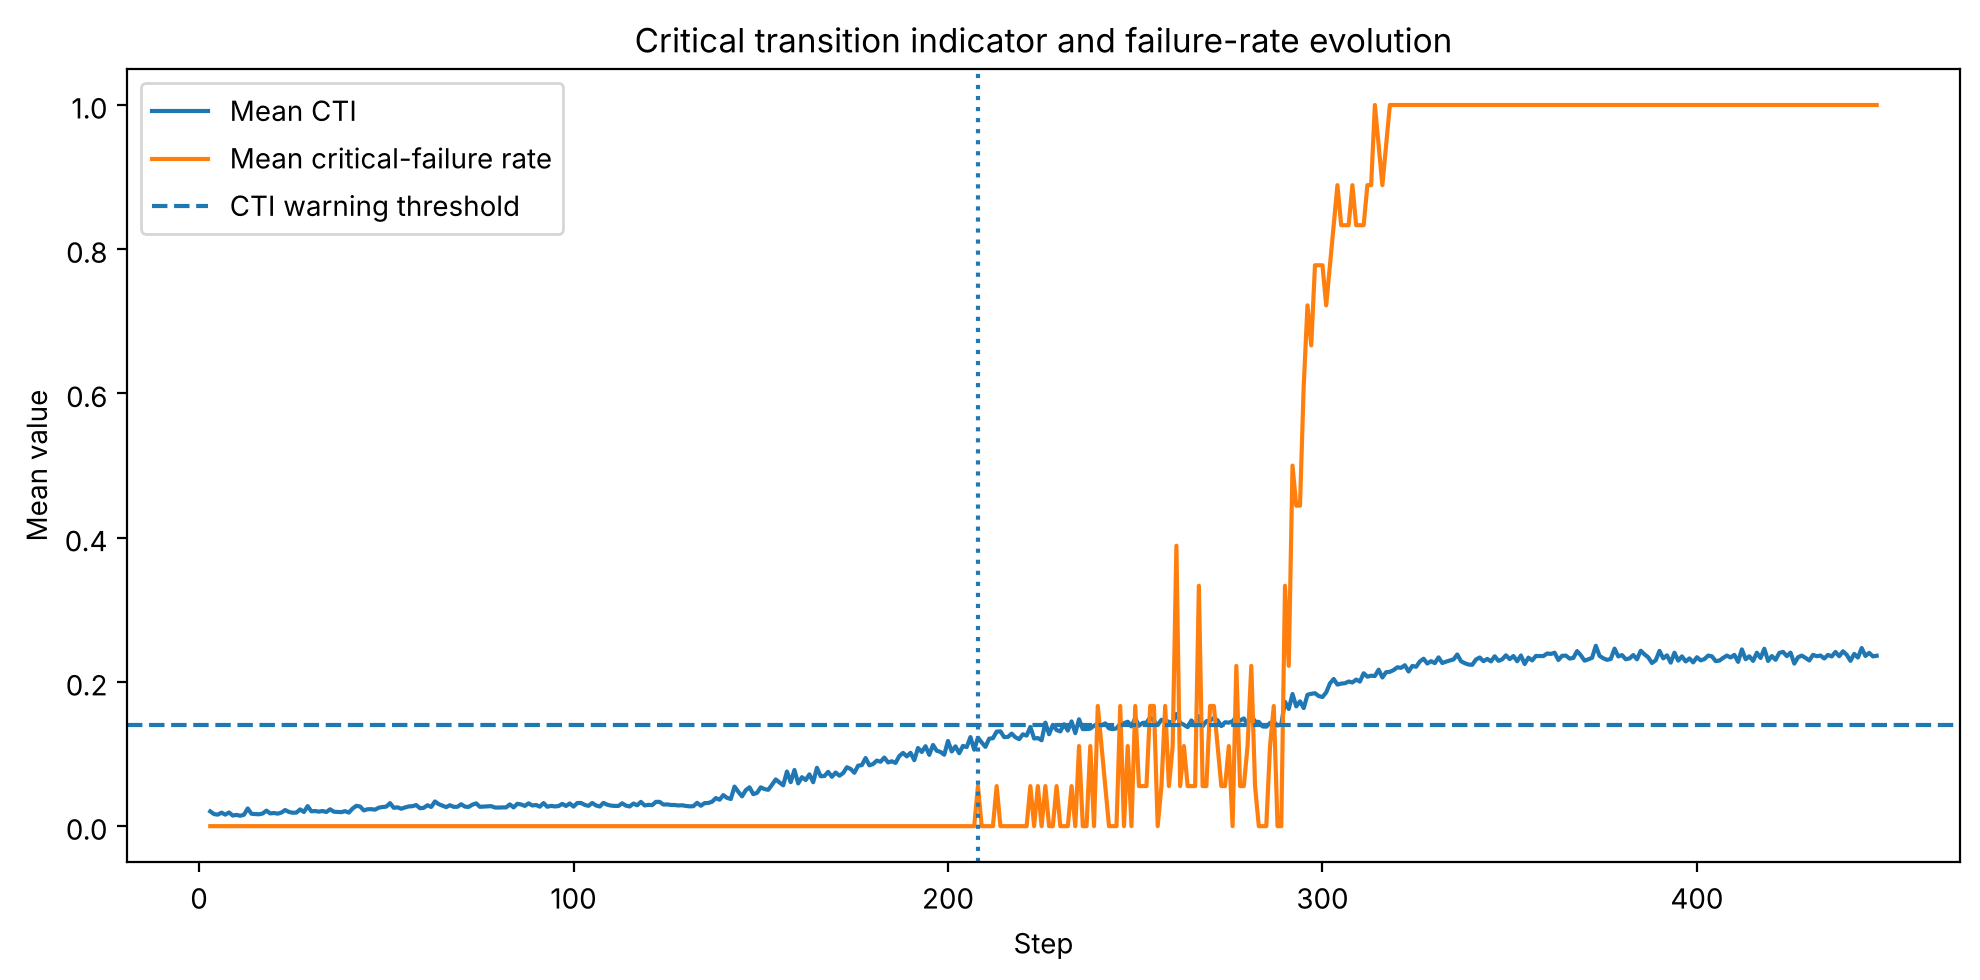

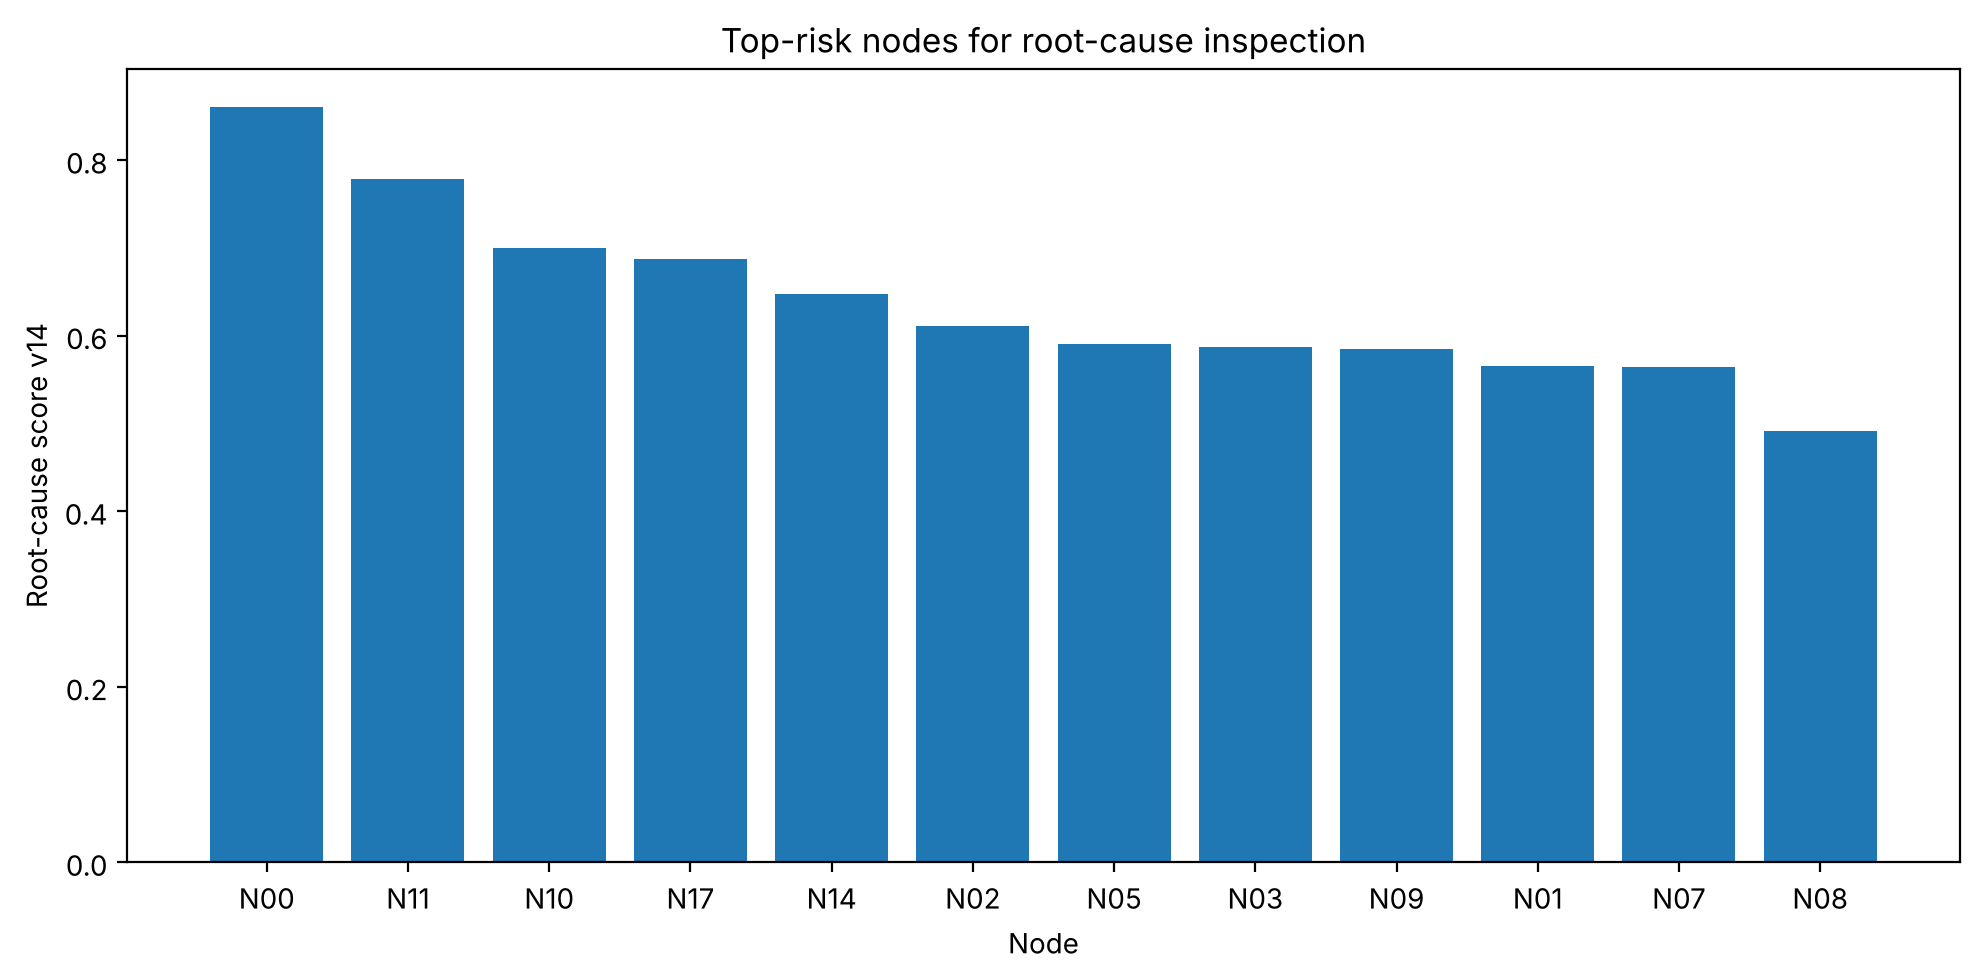

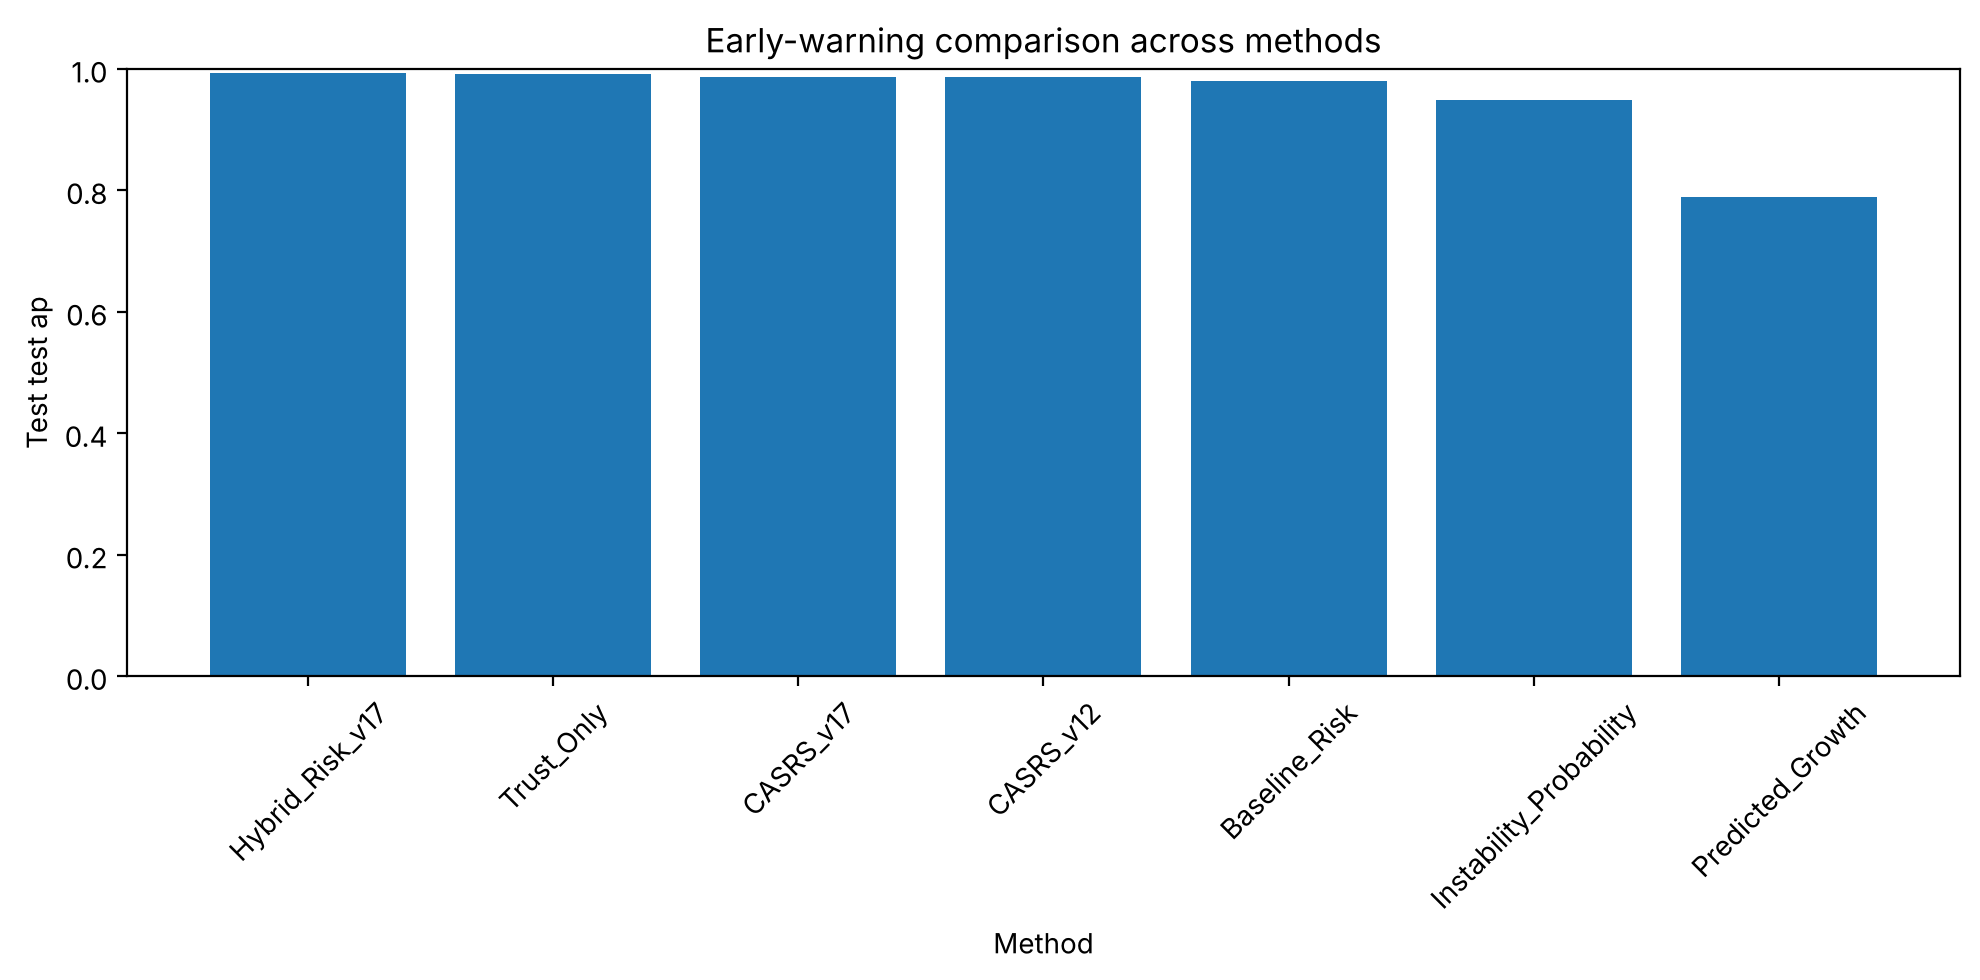

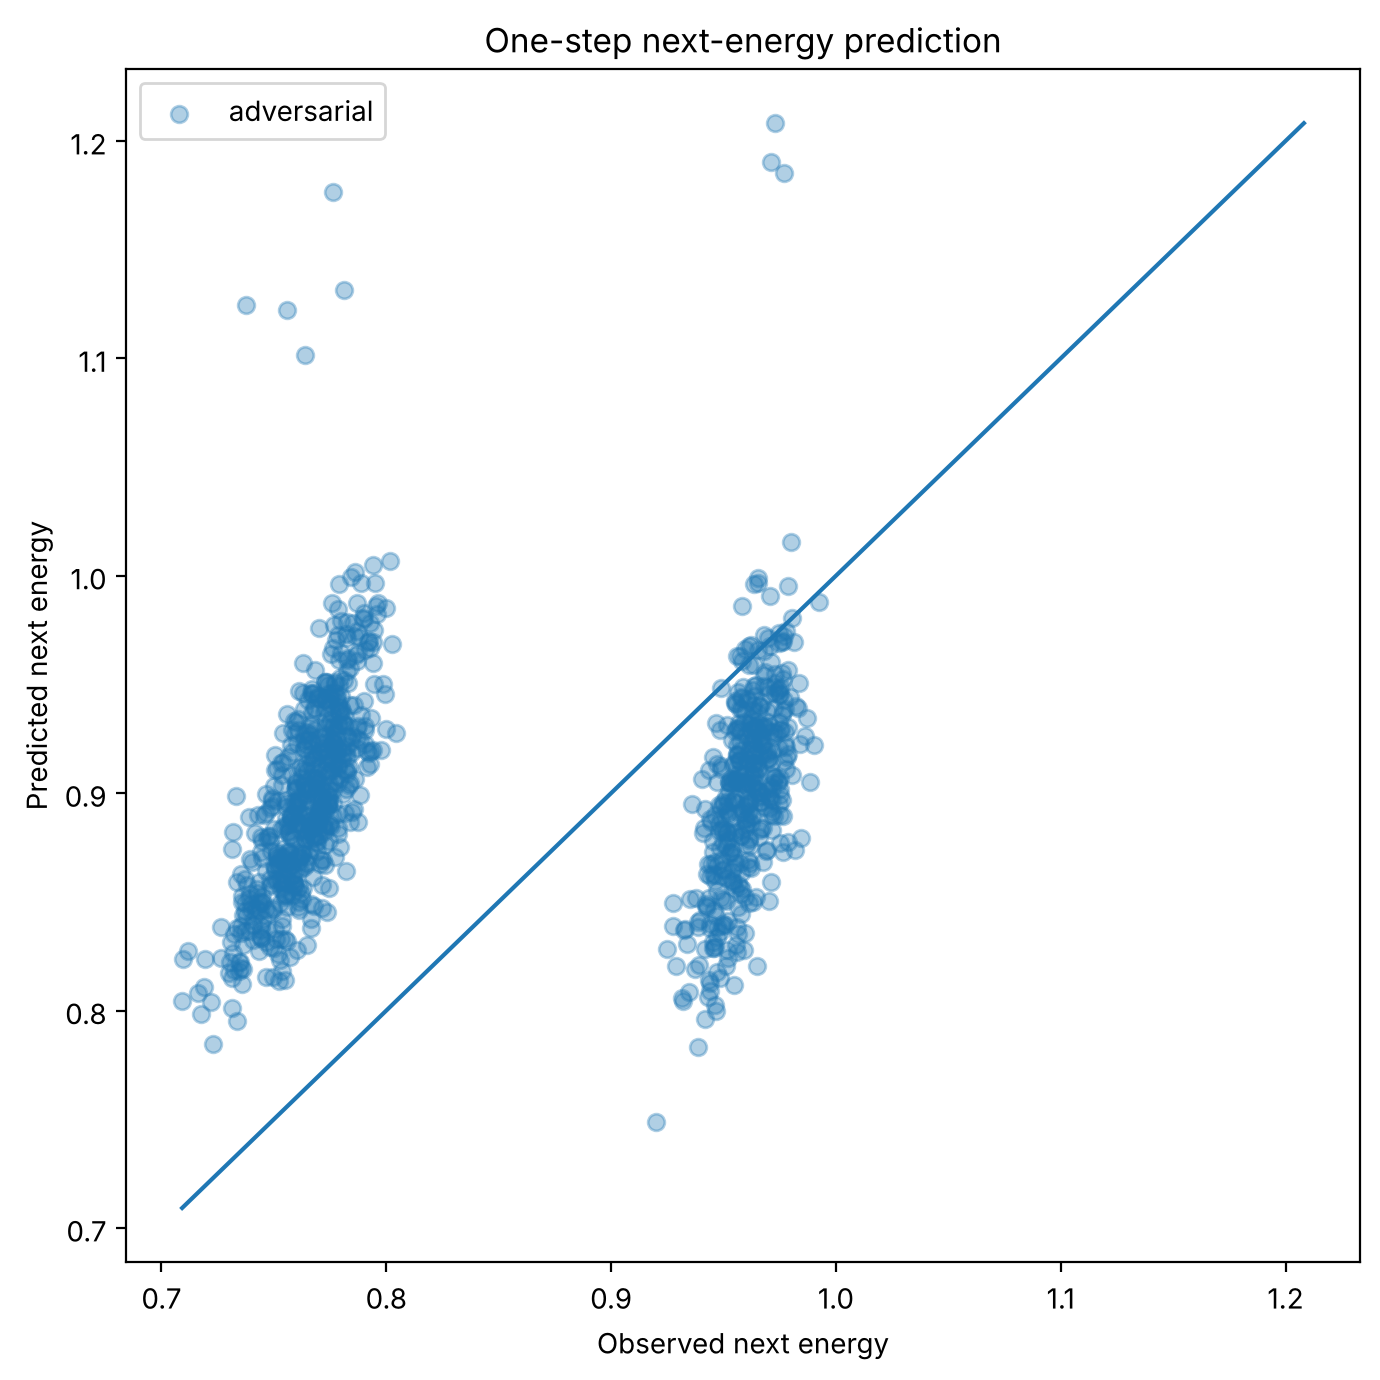

Saved figures:
- outputs/figures/figure_01_scenario_energy_trajectory_v17.png
- outputs/figures/figure_02_nonlinear_phase_plane_v17.png
- outputs/figures/figure_03_cti_vs_failure_rate_v17.png
- outputs/figures/figure_04_top_risk_nodes_v17.png
- outputs/figures/figure_05_method_comparison_v17.png
- outputs/figures/figure_06_next_energy_prediction_v17.png
Saved tables:
- outputs/tables/scenario_energy_summary_v17.csv
- outputs/tables/scenario_failure_summary_v17.csv
- outputs/tables/risk_state_distribution_v17.csv
- outputs/tables/action_summary_v17.csv
- outputs/tables/worst_nodes_v17.csv
- outputs/tables/lead_times_v17.csv
- outputs/tables/lead_time_summary_v17.csv
- outputs/tables/operator_view_v17.csv
- outputs/tables/residual_regression_evaluation_v17.csv
- outputs/tables/instability_classifier_evaluation_v17.csv
- outputs/tables/blend_evaluation_v17.csv
- outputs/tables/final_method_comparison_v17.csv
- outputs/tables/one_step_simulation_eval_v17.csv
- outputs/tables/scenario_regre

In [11]:
# ============================================================
# 9. v17 FIGURES, TABLES, AND DECISION OUTPUTS
# ============================================================

# Scenario summaries
scenario_energy_summary = (
    hybrid_df.groupby("scenario")[[
        "risk_energy", "energy_velocity", "energy_curvature", "energy_dissipation",
        "latent_instability", "resilience_index", "energy_norm", "memory_norm",
        "pressure_norm", "stability_margin", "critical_transition_indicator", "casrs_v14", "hybrid_risk_v14"
    ]]
    .mean()
    .round(4)
    .reset_index()
)

scenario_failure_summary = (
    hybrid_df.groupby("scenario")[["critical_failure", "future_shock", "future_critical_failure_10"]]
    .mean()
    .round(4)
    .reset_index()
)

risk_state_distribution_v14 = pd.crosstab(
    hybrid_df["scenario"],
    hybrid_df["hybrid_state_v14"],
    normalize="index"
).round(4).reset_index()

action_summary_v14 = (
    alerts_df.groupby(["scenario", "recommended_action"])
    .size()
    .reset_index(name="count")
    .sort_values(["scenario", "count"], ascending=[True, False])
)

node_rank_df = hybrid_df.groupby("node").agg(
    mean_hybrid_risk=("hybrid_risk_v14", "mean"),
    mean_casrs=("casrs_v14", "mean"),
    mean_cti=("critical_transition_indicator", "mean"),
    critical_failures=("critical_failure", "sum"),
    mean_pressure=("pressure_norm", "mean"),
    mean_energy=("energy_norm", "mean"),
    mean_instability_prob=("instability_probability", "mean"),
    mean_betweenness=("betweenness", "mean"),
    mean_degree=("degree_norm", "mean"),
).reset_index()

for col in [
    "mean_hybrid_risk", "mean_casrs", "mean_cti", "critical_failures",
    "mean_pressure", "mean_energy", "mean_instability_prob", "mean_betweenness", "mean_degree"
]:
    cmin, cmax = node_rank_df[col].min(), node_rank_df[col].max()
    node_rank_df[f"{col}_norm"] = 0.0 if cmax - cmin < 1e-12 else (node_rank_df[col] - cmin) / (cmax - cmin)

node_rank_df["root_cause_score_v14"] = (
    0.24 * node_rank_df["mean_hybrid_risk_norm"]
    + 0.14 * node_rank_df["mean_cti_norm"]
    + 0.16 * node_rank_df["critical_failures_norm"]
    + 0.12 * node_rank_df["mean_pressure_norm"]
    + 0.10 * node_rank_df["mean_energy_norm"]
    + 0.10 * node_rank_df["mean_instability_prob_norm"]
    + 0.08 * node_rank_df["mean_betweenness_norm"]
    + 0.06 * node_rank_df["mean_degree_norm"]
)
worst_nodes_v14 = node_rank_df.sort_values("root_cause_score_v14", ascending=False).reset_index(drop=True)

# Lead-time extraction based on CTI threshold crossing before first failure
lead_times = []
cti_threshold = float(np.quantile(hybrid_df.loc[hybrid_df["step"] <= train_cut, "critical_transition_indicator"], 0.90))
for node, g in hybrid_df.sort_values("step").groupby("node"):
    g = g.sort_values("step").copy()
    fail_steps = g.loc[g["critical_failure"] == 1, "step"].tolist()
    if len(fail_steps) == 0:
        continue
    first_fail = int(fail_steps[0])
    pre = g[g["step"] < first_fail]
    warned = pre[pre["critical_transition_indicator"] >= cti_threshold]
    if len(warned) > 0:
        first_warn = int(warned["step"].iloc[0])
        lead_times.append({
            "node": node,
            "first_warning_step": first_warn,
            "first_failure_step": first_fail,
            "lead_time_steps": int(first_fail - first_warn),
        })

lead_time_df = pd.DataFrame(lead_times)
lead_time_summary_df = pd.DataFrame([{
    "cti_warning_threshold": cti_threshold,
    "mean_lead_time_steps": float(lead_time_df["lead_time_steps"].mean()) if len(lead_time_df) else np.nan,
    "median_lead_time_steps": float(lead_time_df["lead_time_steps"].median()) if len(lead_time_df) else np.nan,
    "max_lead_time_steps": float(lead_time_df["lead_time_steps"].max()) if len(lead_time_df) else np.nan,
    "n_nodes_with_warning": int(len(lead_time_df)),
}])

top_operator_view_v14 = (
    hybrid_df.sort_values(["step", "hybrid_risk_v14"], ascending=[True, False])
    .groupby("step")
    .head(CONFIG["alert_budget_per_step"])
    [["step", "scenario", "node", "node_type", "hybrid_risk_v14", "hybrid_state_v14",
      "trust", "latency_ms", "packet_loss", "stability_margin", "critical_transition_indicator",
      "recommended_action"]]
    .copy()
)

# Save tables
saved_tables = []
for df, name in [
    (scenario_energy_summary, "scenario_energy_summary_v17.csv"),
    (scenario_failure_summary, "scenario_failure_summary_v17.csv"),
    (risk_state_distribution_v14, "risk_state_distribution_v17.csv"),
    (action_summary_v14, "action_summary_v17.csv"),
    (worst_nodes_v14, "worst_nodes_v17.csv"),
    (lead_time_df, "lead_times_v17.csv"),
    (lead_time_summary_df, "lead_time_summary_v17.csv"),
    (top_operator_view_v14, "operator_view_v17.csv"),
    (model_eval_df, "residual_regression_evaluation_v17.csv"),
    (instability_cls_eval_df, "instability_classifier_evaluation_v17.csv"),
    (blend_eval_df, "blend_evaluation_v17.csv"),
    (hybrid_comparison_df, "final_method_comparison_v17.csv"),
    (sim_eval_df, "one_step_simulation_eval_v17.csv"),
    (scenario_reg_eval_df, "scenario_regression_evaluation_v17.csv"),
]:
    saved_tables.append(save_csv(df, name, index=False))

# -----------------------------
# Figure 1: Mean energy by step and scenario
# -----------------------------
energy_by_step = hybrid_df.groupby(["step", "scenario"])["risk_energy"].mean().reset_index()
transition_step = int(
    energy_by_step.pivot(index="step", columns="scenario", values="risk_energy").ffill().fillna(0.0)
    .assign(gap=lambda x: x.max(axis=1) - x.min(axis=1))
    ["gap"]
    .idxmax()
)

fig, ax = plt.subplots(figsize=(10, 5))
for scen, g in energy_by_step.groupby("scenario"):
    ax.plot(g["step"], g["risk_energy"], label=scen)
ax.axvline(transition_step, linestyle="--")
ax.annotate("critical transition", xy=(transition_step, energy_by_step["risk_energy"].max()*0.92),
            xytext=(transition_step + 8, energy_by_step["risk_energy"].max()*0.80),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Step")
ax.set_ylabel("Mean risk energy")
ax.set_title("Scenario-wise mean risk energy trajectory")
ax.legend()
fig1_path = save_figure(fig, "figure_01_scenario_energy_trajectory_v17.png")
plt.show()

# -----------------------------
# Figure 2: Nonlinear phase plane
# -----------------------------
sample_df = hybrid_df.sample(min(1800, len(hybrid_df)), random_state=SEED).copy()
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(sample_df["phase_x_v14"], sample_df["phase_y_v14"],
                c=sample_df["critical_transition_indicator"], alpha=0.35)
ax.axhline(0.0)
ax.axvline(0.0)
ax.set_xlabel("Nonlinear stability coordinate")
ax.set_ylabel("Nonlinear analytical velocity")
ax.set_title("Instability boundary in the nonlinear analytical phase plane")
plt.colorbar(sc, ax=ax, label="CTI")
fig2_path = save_figure(fig, "figure_02_nonlinear_phase_plane_v17.png")
plt.show()

# -----------------------------
# Figure 3: Critical transition indicator versus failures
# -----------------------------
phi_by_step = hybrid_df.groupby("step")["critical_transition_indicator"].mean()
fail_by_step = hybrid_df.groupby("step")["critical_failure"].mean()
first_fail_step = int(hybrid_df.loc[hybrid_df["critical_failure"] == 1, "step"].min()) if (hybrid_df["critical_failure"] == 1).any() else None
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(phi_by_step.index, phi_by_step.values, label="Mean CTI")
ax.plot(fail_by_step.index, fail_by_step.values, label="Mean critical-failure rate")
ax.axhline(cti_threshold, linestyle="--", label="CTI warning threshold")
if first_fail_step is not None:
    ax.axvline(first_fail_step, linestyle=":")
ax.set_xlabel("Step")
ax.set_ylabel("Mean value")
ax.set_title("Critical transition indicator and failure-rate evolution")
ax.legend()
fig3_path = save_figure(fig, "figure_03_cti_vs_failure_rate_v17.png")
plt.show()

# -----------------------------
# Figure 4: Top-risk node ranking
# -----------------------------
top_nodes = worst_nodes_v14.head(12).copy()
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(top_nodes["node"], top_nodes["root_cause_score_v14"])
ax.set_xlabel("Node")
ax.set_ylabel("Root-cause score v14")
ax.set_title("Top-risk nodes for root-cause inspection")
fig4_path = save_figure(fig, "figure_04_top_risk_nodes_v17.png")
plt.show()

# -----------------------------
# Figure 5: Method comparison
# -----------------------------
plot_df = hybrid_comparison_df.copy()
metric_col = "test_ap" if ("test_ap" in plot_df.columns and plot_df["test_ap"].notna().any()) else "test_roc_auc"
plot_df = plot_df.dropna(subset=[metric_col]).copy()
fig, ax = plt.subplots(figsize=(10, 5))
if len(plot_df) > 0:
    ax.bar(plot_df["method"], plot_df[metric_col])
    ax.set_ylim(0.0, min(1.0, max(0.55, plot_df[metric_col].max() * 1.10)))
else:
    ax.text(0.5, 0.5, "No valid comparison values", ha="center", va="center")
ax.set_xlabel("Method")
ax.set_ylabel(f"Test {metric_col.replace('_', ' ')}")
ax.set_title("Early-warning comparison across methods")
ax.tick_params(axis='x', rotation=45)
fig5_path = save_figure(fig, "figure_05_method_comparison_v17.png")
plt.show()

# -----------------------------
# Figure 6: One-step energy prediction quality
# -----------------------------
pred_plot = sim_eval_df.sample(min(1000, len(sim_eval_df)), random_state=SEED)
fig, ax = plt.subplots(figsize=(7, 7))
for scen, g in pred_plot.groupby("scenario"):
    ax.scatter(g["next_energy"], g["predicted_next_energy"], alpha=0.35, label=scen)
mn = min(pred_plot["next_energy"].min(), pred_plot["predicted_next_energy"].min())
mx = max(pred_plot["next_energy"].max(), pred_plot["predicted_next_energy"].max())
ax.plot([mn, mx], [mn, mx])
ax.set_xlabel("Observed next energy")
ax.set_ylabel("Predicted next energy")
ax.set_title("One-step next-energy prediction")
ax.legend()
fig6_path = save_figure(fig, "figure_06_next_energy_prediction_v17.png")
plt.show()

print("=" * 100)
print("Saved figures:")
for p in [fig1_path, fig2_path, fig3_path, fig4_path, fig5_path, fig6_path]:
    print("-", p)
print("=" * 100)

print("Saved tables:")
for p in saved_tables:
    print("-", p)
print("=" * 100)

print("Scenario energy summary")
print(scenario_energy_summary)
print("=" * 100)
print("Final method comparison")
print(hybrid_comparison_df.round(4))
print("=" * 100)
print("Lead-time summary")
print(lead_time_summary_df.round(4))
print("=" * 100)
print("Top operator view")
print(top_operator_view_v14.head(20))

## 11b. Persistence baseline for the one-step forecast

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_true = test_df["next_energy"]; y_persist = test_df["risk_energy"]
persistence_df = pd.DataFrame([{"forecast": "Persistence", "mae": mean_absolute_error(y_true, y_persist),
    "rmse": mean_squared_error(y_true, y_persist) ** 0.5, "r2": r2_score(y_true, y_persist), "n": len(y_true)}]).round(4)
print(pd.concat([scenario_reg_eval_df.round(4).assign(forecast="Residual model"), persistence_df]).to_string(index=False))
save_csv(persistence_df, "persistence_baseline.csv")

   scenario    mae   rmse      r2    n       forecast
adversarial 0.1035 0.1151 -0.3982 1620 Residual model
        NaN 0.0916 0.1287 -0.7471 1620    Persistence


PosixPath('outputs/tables/persistence_baseline.csv')

## 12. Sensitivity to the threshold quantile and to the CTI weights
The CTI is recomputed from its six components so that each weight can be perturbed. For every draw the 90th-percentile threshold of the training window (steps 3–268) is recomputed. The node ranking examined is the mean-CTI ranking.

In [13]:
from scipy.stats import spearmanr

TRAIN_CUT = 268
H = hybrid_df.sort_values(["node", "step"]).reset_index(drop=True)
W0 = {"velocity": 0.38, "curvature": 0.24, "memory": 0.16, "pressure": 0.10, "acceleration": 0.06, "entropy": 0.06}
COMP = pd.DataFrame({
    "velocity": np.maximum(H["energy_velocity"], 0.0),
    "curvature": np.maximum(H["energy_curvature"], 0.0),
    "memory": H["memory_norm"],
    "pressure": H["pressure_norm"],
    "acceleration": np.maximum(H["risk_delta"], 0.0),
    "entropy": H["energy_entropy"],
})
def cti_from(w):
    return np.clip(sum(w[k] * COMP[k] for k in W0), 0.0, 1.0)
assert np.allclose(cti_from(W0), H["critical_transition_indicator"]), "CTI reconstruction mismatch"

FIRST_FAIL = H[H["critical_failure"] == 1].groupby("node")["step"].min()
H["first_fail"] = H["node"].map(FIRST_FAIL)
IS_TRAIN = H["step"] <= TRAIN_CUT
IS_NOMINAL = H["scenario"] == "nominal"
PRE = H["step"] < H["first_fail"]
CTI = H["critical_transition_indicator"]

def lead_times(score, tau, valid=None):
    flag = (score >= tau) & PRE
    if valid is not None:
        flag &= valid
    first_warn = H[flag].groupby("node")["step"].min()
    return FIRST_FAIL[first_warn.index] - first_warn

rows = []
for q in [0.80, 0.85, 0.90, 0.925, 0.95]:
    tau = float(np.quantile(CTI[IS_TRAIN], q)); L = lead_times(CTI, tau)
    rows.append({"quantile": q, "tau": round(tau, 4), "mean_lead": round(L.mean(), 1), "median_lead": L.median(),
                 "max_lead": int(L.max()), "nodes_warned": f"{len(L)}/18"})
sens_threshold_df = pd.DataFrame(rows)
print("Threshold sensitivity"); print(sens_threshold_df.to_string(index=False))
max_pre_cti = CTI[PRE].groupby(H["node"][PRE]).max()
print(f"All failing nodes remain warned for any tau <= {max_pre_cti.min():.4f}")
save_csv(sens_threshold_df, "sensitivity_threshold.csv")

base_rank = H.groupby("node")["critical_transition_indicator"].mean()
base_top10 = set(base_rank.nlargest(10).index)
rng = np.random.default_rng(42)
draws = []
for d in range(200):
    f = rng.uniform(0.8, 1.2, size=6)
    w = {k: W0[k] * f[i] for i, k in enumerate(W0)}
    s = cti_from(w); tau = float(np.quantile(s[IS_TRAIN], 0.90)); L = lead_times(s, tau)
    r = pd.Series(s.values, index=H["node"]).groupby(level=0).mean()
    draws.append({"draw": d, "tau": tau, "mean_lead": L.mean(), "nodes_warned": len(L),
                  "spearman_rho": spearmanr(r[base_rank.index], base_rank).statistic,
                  "top10_overlap": len(set(r.nlargest(10).index) & base_top10)})
    if (d + 1) % 50 == 0:
        print(f"  weight perturbation: {d + 1}/200 draws done")
sens_weights_df = pd.DataFrame(draws)
sens_weights_summary = sens_weights_df.drop(columns="draw").agg(["mean", "std", "min", "max"]).T.round(4)
print("Weight perturbation (200 draws, +/-20%, seed 42)"); print(sens_weights_summary)
save_csv(sens_weights_df, "sensitivity_weights_draws.csv")
save_csv(sens_weights_summary.reset_index().rename(columns={"index": "quantity"}), "sensitivity_weights_summary.csv")

Threshold sensitivity
 quantile    tau  mean_lead  median_lead  max_lead nodes_warned
    0.800 0.1189      102.3         94.0       200        18/18
    0.850 0.1301       86.3         79.0       143        18/18
    0.900 0.1406       74.9         65.5       118        18/18
    0.925 0.1451       69.6         61.0       115        18/18
    0.950 0.1549       63.6         55.5       110        18/18
All failing nodes remain warned for any tau <= 0.1745


  weight perturbation: 50/200 draws done


  weight perturbation: 100/200 draws done


  weight perturbation: 150/200 draws done


  weight perturbation: 200/200 draws done
Weight perturbation (200 draws, +/-20%, seed 42)
                  mean     std      min      max
tau             0.1408  0.0098   0.1149   0.1635
mean_lead      75.2311  5.5865  63.5556  88.5556
nodes_warned   18.0000  0.0000  18.0000  18.0000
spearman_rho    0.9960  0.0040   0.9835   1.0000
top10_overlap   9.8850  0.3198   9.0000  10.0000


PosixPath('outputs/tables/sensitivity_weights_summary.csv')

## 13. Comparison with single CTI terms and critical-slowing-down statistics
Every indicator is thresholded at the 99th percentile of its nominal-regime values (target 1 % nominal alarms). Rolling statistics of the node risk energy use a trailing window of 20 steps with at least 10 observations. The variance + AC(1) composite averages empirical ranks fitted on the training window. Discrimination targets a critical failure within the next 10 steps over pre-failure node-steps.

In [14]:
from sklearn.metrics import roc_auc_score, average_precision_score

def future_failure(g, horizon=10):
    f = g["critical_failure"].to_numpy(); n = len(f)
    return pd.Series([int(f[i + 1:i + 1 + horizon].max()) if i + 1 < n else 0 for i in range(n)], index=g.index)
H["fail_within_10"] = H.groupby("node", group_keys=False).apply(future_failure)

print("Computing rolling statistics (window 20, min 10)...")
E = H.groupby("node")["risk_energy"]
def _ac1(x):
    a, b = x[:-1], x[1:]
    return np.nan if a.std() == 0 or b.std() == 0 else np.corrcoef(a, b)[0, 1]
H["roll_var"] = E.transform(lambda s: s.rolling(20, min_periods=10).var())
H["roll_ac1"] = E.transform(lambda s: s.rolling(20, min_periods=10).apply(_ac1, raw=True))
H["roll_skew"] = E.transform(lambda s: s.rolling(20, min_periods=10).skew())
def _train_rank(col):
    ref = np.sort(H.loc[IS_TRAIN, col].dropna().to_numpy())
    return pd.Series(np.searchsorted(ref, H[col].to_numpy(), side="right") / len(ref), index=H.index).where(H[col].notna())
H["var_ac1_composite"] = (_train_rank("roll_var") + _train_rank("roll_ac1")) / 2
print("Rolling statistics ready.")

INDICATORS = [
    ("Proposed", "CTI (six-term fusion)", CTI),
    ("Single CTI term", "Velocity only", COMP["velocity"]),
    ("Single CTI term", "Curvature only", COMP["curvature"]),
    ("Single CTI term", "Memory only", COMP["memory"]),
    ("Single CTI term", "Pressure only", COMP["pressure"]),
    ("Classical CSD", "Rolling variance", H["roll_var"]),
    ("Classical CSD", "Lag-1 autocorrelation", H["roll_ac1"]),
    ("Classical CSD", "Rolling skewness", H["roll_skew"]),
    ("Classical CSD", "Variance + AC(1) composite", H["var_ac1_composite"]),
]
rows = []
for family, name, s in INDICATORS:
    valid = s.notna()
    tau = float(np.quantile(s[IS_NOMINAL & valid], 0.99))
    L = lead_times(s, tau, valid)
    m = PRE & valid
    rows.append({"family": family, "indicator": name, "nodes_warned": f"{len(L)}/18",
                 "mean_lead": round(L.mean(), 1), "median_lead": L.median(),
                 "roc_auc": round(roc_auc_score(H.loc[m, "fail_within_10"], s[m]), 4),
                 "ap": round(average_precision_score(H.loc[m, "fail_within_10"], s[m]), 4),
                 "n_eval": int(m.sum()), "positives": int(H.loc[m, "fail_within_10"].sum()),
                 "nominal_alarm_rate_pct": round(100 * (s[IS_NOMINAL & valid] >= tau).mean(), 3)})
csd_comparison_df = pd.DataFrame(rows)
print(csd_comparison_df.to_string(index=False))
save_csv(csd_comparison_df, "csd_comparison.csv")

REL = H["step"] - H["first_fail"]
aligned = {}
for name, s in [("CTI", CTI), ("Rolling variance", H["roll_var"]), ("Lag-1 autocorrelation", H["roll_ac1"])]:
    z = (s - s[IS_NOMINAL].mean()) / s[IS_NOMINAL].std()
    grp = z[(REL >= -150) & (REL <= -1)].groupby(REL[(REL >= -150) & (REL <= -1)])
    aligned[name] = pd.DataFrame({"median": grp.median(), "q25": grp.quantile(0.25), "q75": grp.quantile(0.75)})
    print(f"{name}: median standardized value one step before failure = {aligned[name]['median'].loc[-1]:.2f}")

Computing rolling statistics (window 20, min 10)...


Rolling statistics ready.
         family                  indicator nodes_warned  mean_lead  median_lead  roc_auc     ap  n_eval  positives  nominal_alarm_rate_pct
       Proposed      CTI (six-term fusion)        18/18      156.2        158.0   0.9470 0.3443    4626        180                   1.014
Single CTI term              Velocity only        18/18      176.9        182.5   0.5971 0.0993    4626        180                   1.014
Single CTI term             Curvature only        18/18      166.5        165.5   0.5449 0.0717    4626        180                   1.014
Single CTI term                Memory only        18/18      111.1        100.5   0.9741 0.5771    4626        180                   1.014
Single CTI term              Pressure only        18/18      125.4        118.5   0.9257 0.2504    4626        180                   1.014
  Classical CSD           Rolling variance        18/18      115.7        112.0   0.8610 0.1754    4464        180                   1.042
 

## 14. Operator-preference trade-off
The threshold quantile is swept over q = 0.50, ..., 0.99. FAR is the fraction of nominal node-steps flagged; burden is the fraction of pre-failure node-steps flagged.

In [15]:
rows = []
for q in np.round(np.arange(0.50, 0.995, 0.01), 2):
    tau = float(np.quantile(CTI[IS_TRAIN], q)); flag = CTI >= tau
    L = lead_times(CTI, tau)
    rows.append({"q": q, "tau": tau, "nodes_warned": len(L), "mean_lead": L.mean(), "min_lead": L.min(),
                 "nodes_below_48": int((L < 48).sum()),
                 "far_pct": 100 * flag[IS_NOMINAL].mean(), "burden_pct": 100 * flag[PRE].mean()})
tradeoff_df = pd.DataFrame(rows)
full = tradeoff_df[tradeoff_df["nodes_warned"] == 18]
profiles = {
    "Safety-first": full[full["far_pct"] <= 1.0].sort_values("mean_lead").iloc[-1],
    "Balanced": full[full["far_pct"] == 0.0].sort_values("mean_lead").iloc[-1],
    "Paper setting": tradeoff_df[tradeoff_df["q"] == 0.90].iloc[0],
    "Alarm-averse": full[full["mean_lead"] >= 48].sort_values("burden_pct").iloc[0],
}
tradeoff_profiles_df = pd.DataFrame([{"profile": k, **v.to_dict()} for k, v in profiles.items()]).round(4)
print(tradeoff_profiles_df.to_string(index=False))
save_csv(tradeoff_df.round(4), "tradeoff_sweep.csv")
save_csv(tradeoff_profiles_df, "tradeoff_profiles.csv")

      profile    q    tau  nodes_warned  mean_lead  min_lead  nodes_below_48  far_pct  burden_pct
 Safety-first 0.71 0.0986          18.0   149.8333      75.0             0.0   0.8516     26.5240
     Balanced 0.82 0.1232          18.0    93.5556      63.0             0.0   0.0000     13.7700
Paper setting 0.90 0.1406          18.0    74.8889      47.0             1.0   0.0000      6.1608
 Alarm-averse 0.97 0.1676          18.0    50.8333       4.0             9.0   0.0000      2.4211


PosixPath('outputs/tables/tradeoff_profiles.csv')

## 15. Figures 7–9

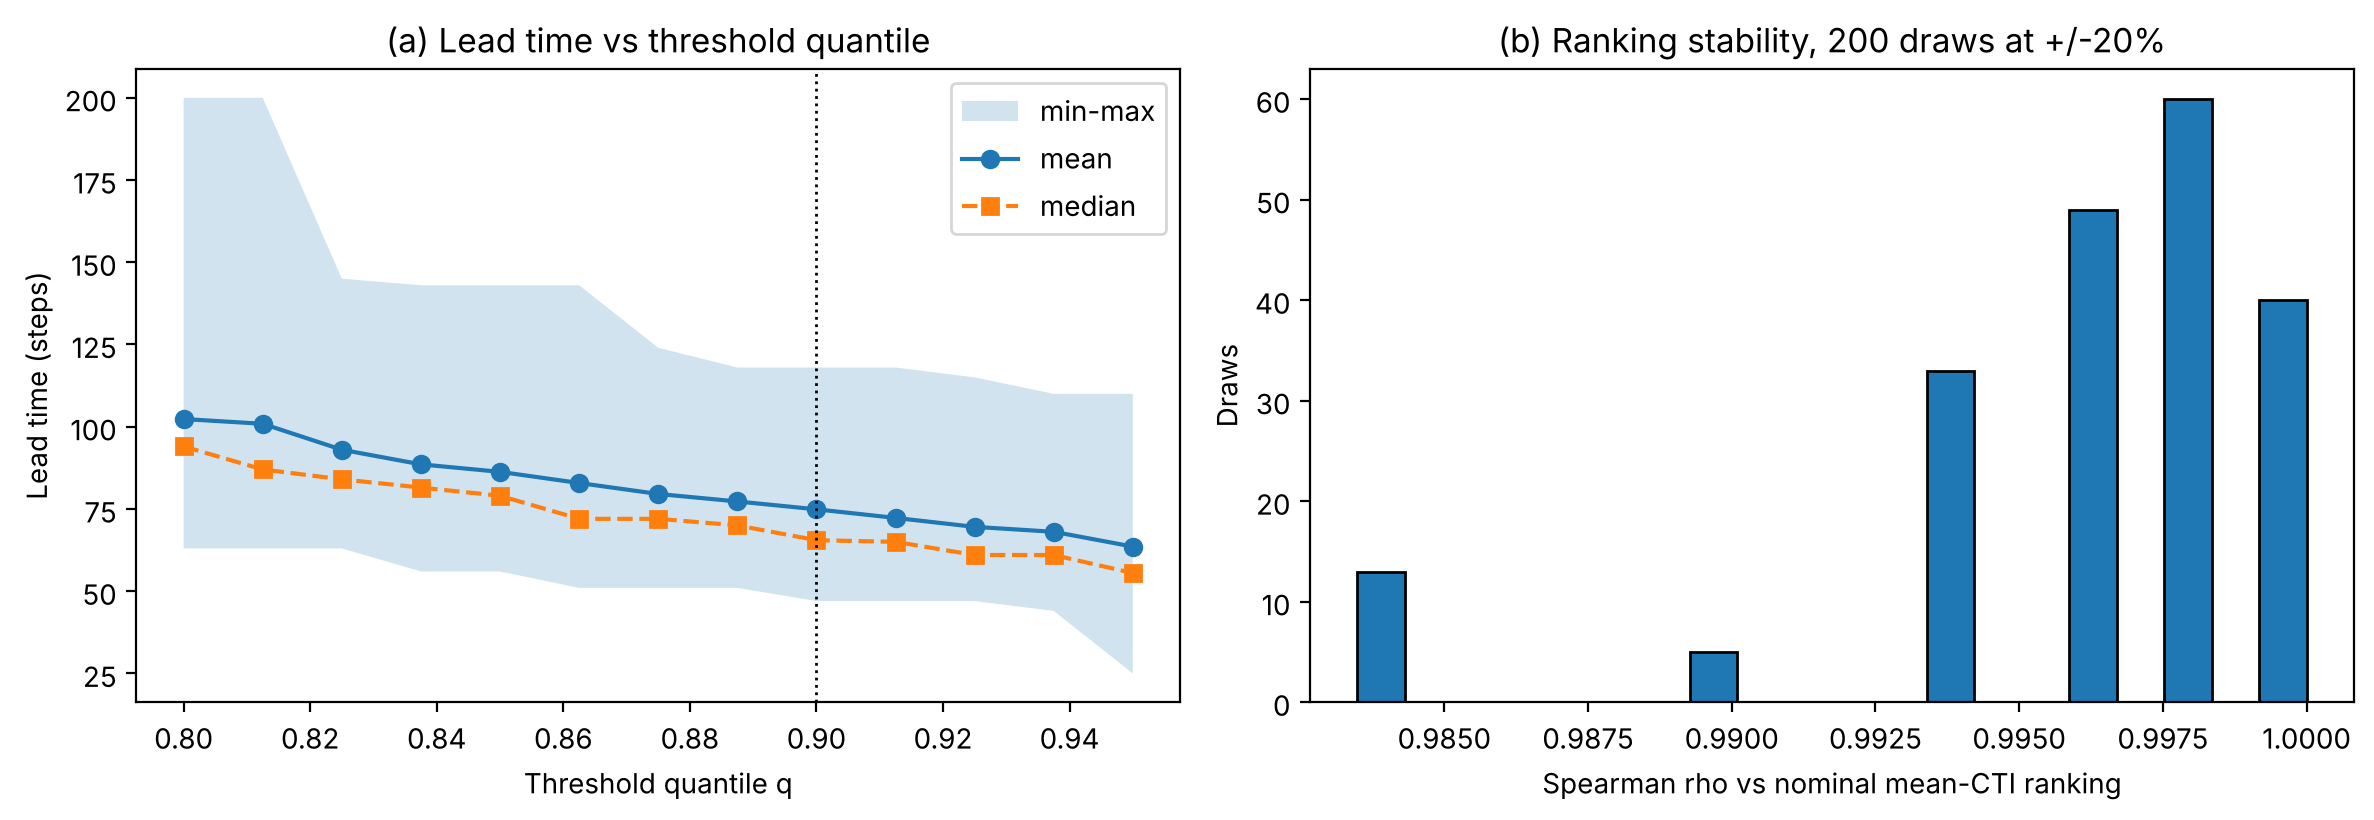

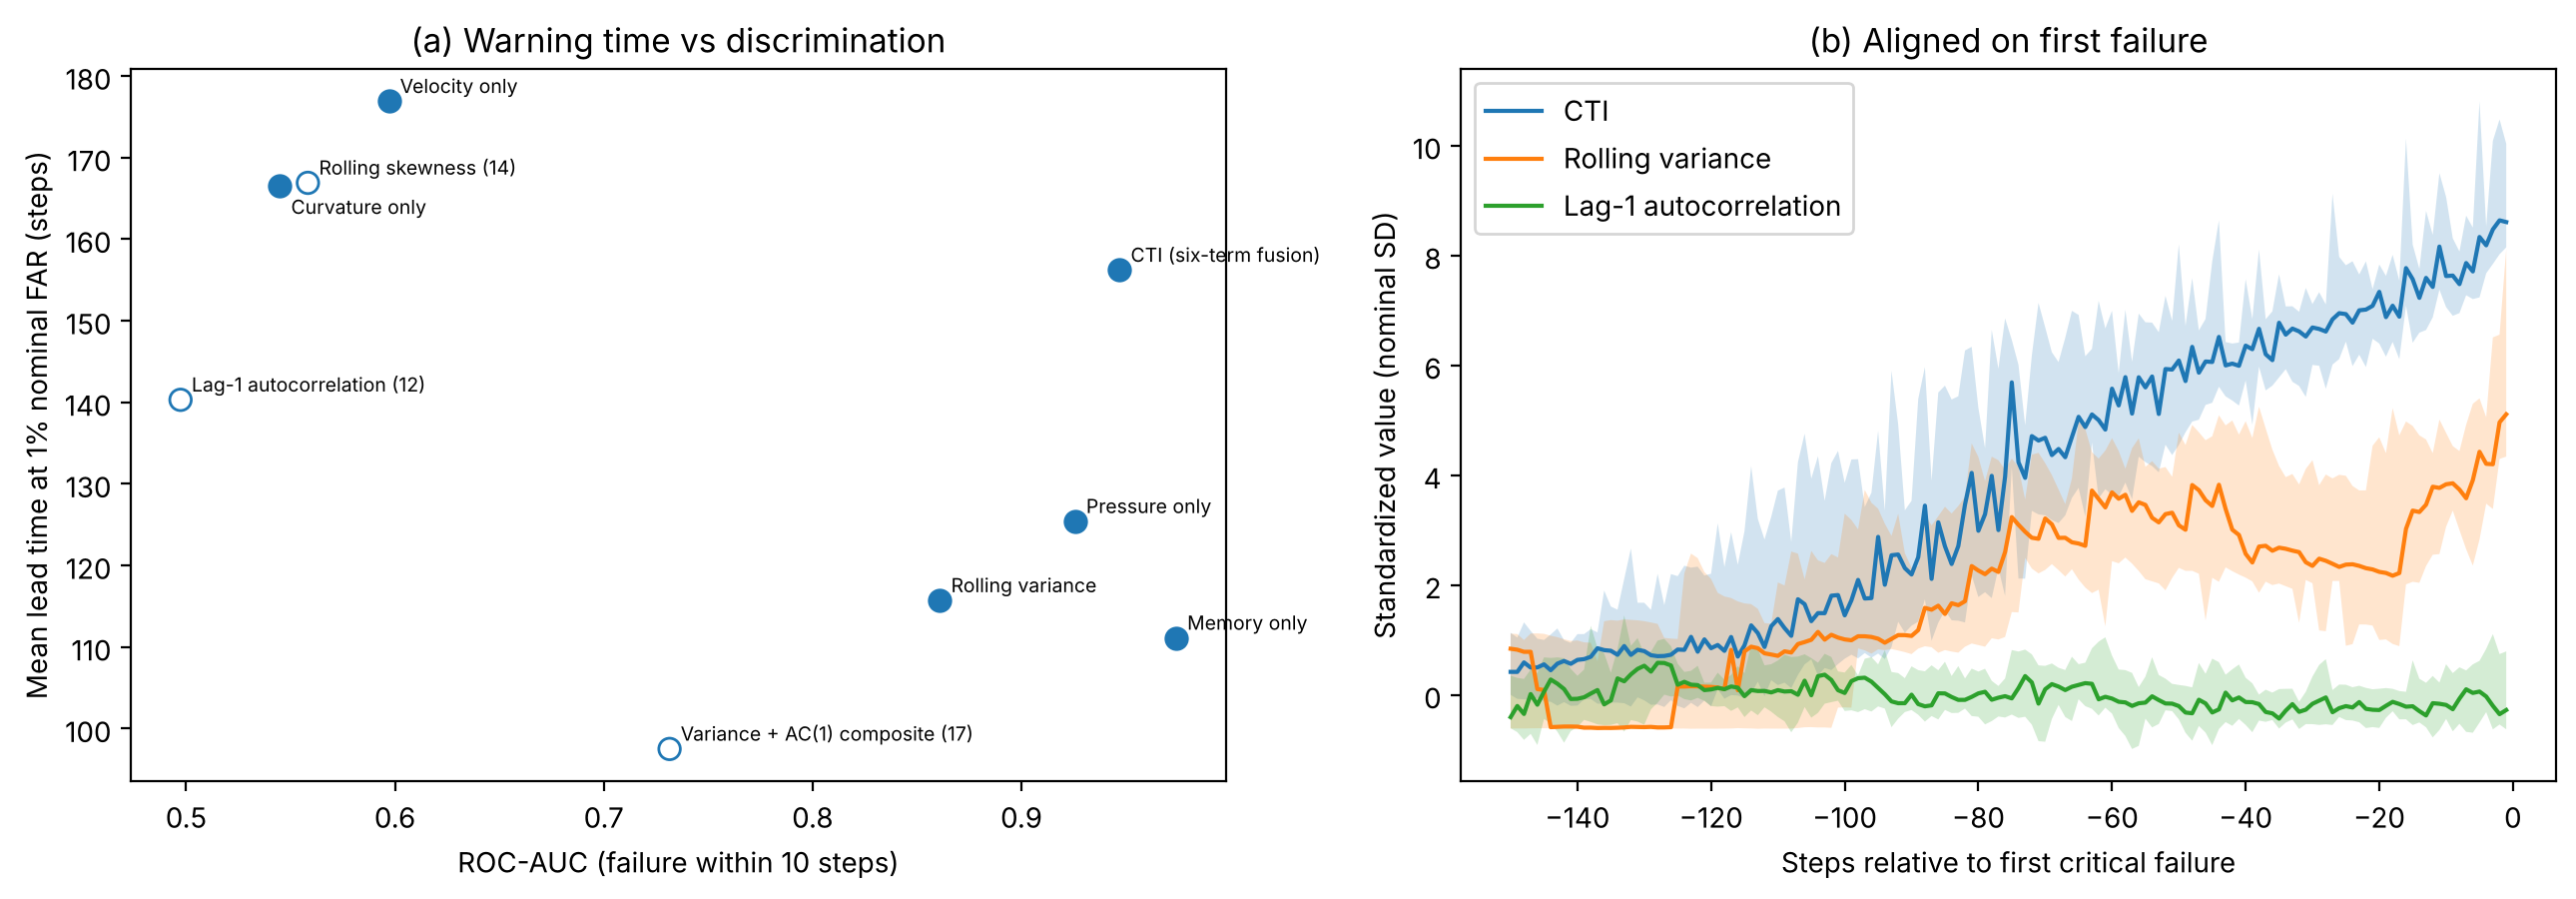

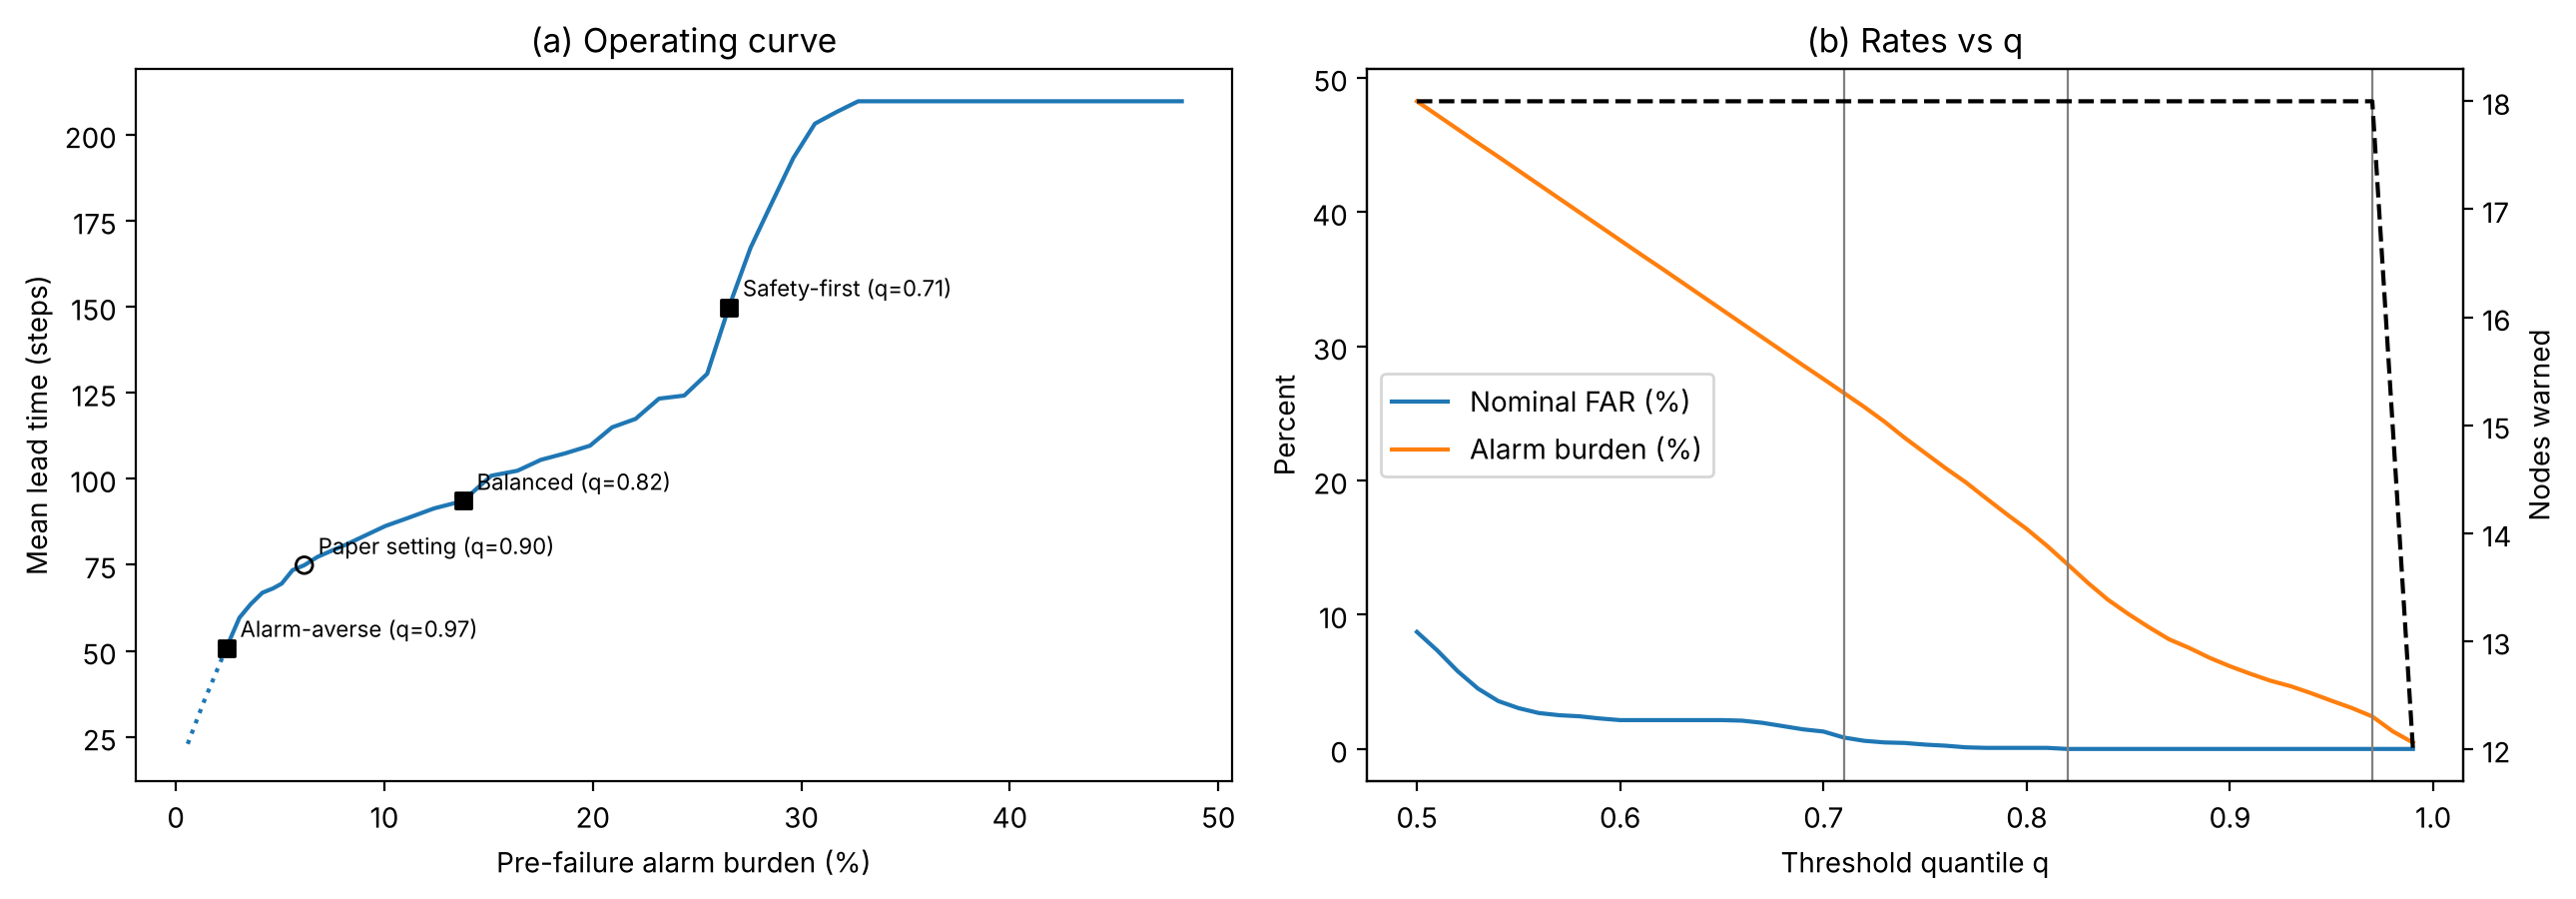

In [16]:
# Figure 7: sensitivity
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
qs = np.round(np.arange(0.80, 0.951, 0.0125), 4); st = []
for q in qs:
    L = lead_times(CTI, float(np.quantile(CTI[IS_TRAIN], q))); st.append((L.mean(), L.median(), L.min(), L.max()))
st = np.array(st)
ax[0].fill_between(qs, st[:, 2], st[:, 3], alpha=0.2, label="min-max")
ax[0].plot(qs, st[:, 0], "o-", label="mean"); ax[0].plot(qs, st[:, 1], "s--", label="median")
ax[0].axvline(0.90, color="k", ls=":", lw=1); ax[0].set_xlabel("Threshold quantile q"); ax[0].set_ylabel("Lead time (steps)")
ax[0].set_title("(a) Lead time vs threshold quantile"); ax[0].legend()
ax[1].hist(sens_weights_df["spearman_rho"], bins=20, edgecolor="k")
ax[1].set_xlabel("Spearman rho vs nominal mean-CTI ranking"); ax[1].set_ylabel("Draws")
ax[1].set_title("(b) Ranking stability, 200 draws at +/-20%")
save_figure(fig, "figure_07_sensitivity.png"); plt.show()

# Figure 8: CTI vs single terms and CSD statistics
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for _, r in csd_comparison_df.iterrows():
    full_cov = r["nodes_warned"] == "18/18"
    ax[0].scatter(r["roc_auc"], r["mean_lead"], s=60, facecolors="C0" if full_cov else "none", edgecolors="C0")
    lbl = r["indicator"] + ("" if full_cov else f" ({r['nodes_warned'].split('/')[0]})")
    ax[0].annotate(lbl, (r["roc_auc"], r["mean_lead"]), fontsize=7, xytext=(4, -10) if r["indicator"] == "Curvature only" else (4, 3), textcoords="offset points")
ax[0].set_xlabel("ROC-AUC (failure within 10 steps)"); ax[0].set_ylabel("Mean lead time at 1% nominal FAR (steps)")
ax[0].set_title("(a) Warning time vs discrimination")
for name, d in aligned.items():
    ax[1].plot(d.index, d["median"], label=name); ax[1].fill_between(d.index, d["q25"], d["q75"], alpha=0.2)
ax[1].set_xlabel("Steps relative to first critical failure"); ax[1].set_ylabel("Standardized value (nominal SD)")
ax[1].set_title("(b) Aligned on first failure"); ax[1].legend()
save_figure(fig, "figure_08_cti_vs_csd.png"); plt.show()

# Figure 9: operator trade-off
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ok = tradeoff_df["nodes_warned"] == 18
ax[0].plot(tradeoff_df.loc[ok, "burden_pct"], tradeoff_df.loc[ok, "mean_lead"], "-")
tail = tradeoff_df[tradeoff_df["q"] >= tradeoff_df.loc[ok, "q"].max()]
ax[0].plot(tail["burden_pct"], tail["mean_lead"], ":", color="C0")
for k, v in profiles.items():
    ax[0].scatter(v["burden_pct"], v["mean_lead"], marker="o" if k == "Paper setting" else "s",
                  facecolors="none" if k == "Paper setting" else "k", edgecolors="k", zorder=3)
    ax[0].annotate(f"{k} (q={v['q']:.2f})", (v["burden_pct"], v["mean_lead"]), fontsize=8, xytext=(5, 4), textcoords="offset points")
ax[0].set_xlabel("Pre-failure alarm burden (%)"); ax[0].set_ylabel("Mean lead time (steps)"); ax[0].set_title("(a) Operating curve")
ax[1].plot(tradeoff_df["q"], tradeoff_df["far_pct"], label="Nominal FAR (%)")
ax[1].plot(tradeoff_df["q"], tradeoff_df["burden_pct"], label="Alarm burden (%)")
ax2 = ax[1].twinx(); ax2.plot(tradeoff_df["q"], tradeoff_df["nodes_warned"], "k--", label="Nodes warned"); ax2.set_ylabel("Nodes warned")
for k in ["Safety-first", "Balanced", "Alarm-averse"]:
    ax[1].axvline(profiles[k]["q"], color="grey", lw=0.8)
ax[1].set_xlabel("Threshold quantile q"); ax[1].set_ylabel("Percent"); ax[1].legend(loc="center left"); ax[1].set_title("(b) Rates vs q")
save_figure(fig, "figure_09_tradeoff.png"); plt.show()

## 16. Summary and Drive copy

In [17]:
summary = {
    "lead_time_q90": lead_time_summary_df.round(4).to_dict(orient="records")[0],
    "threshold_sensitivity": sens_threshold_df.to_dict(orient="records"),
    "weight_sensitivity": sens_weights_summary.reset_index().rename(columns={"index": "quantity"}).to_dict(orient="records"),
    "csd_comparison": csd_comparison_df.to_dict(orient="records"),
    "tradeoff_profiles": tradeoff_profiles_df.to_dict(orient="records"),
    "method_comparison": hybrid_comparison_df.round(4).to_dict(orient="records"),
    "forecast": scenario_reg_eval_df.round(4).to_dict(orient="records"),
    "persistence": persistence_df.to_dict(orient="records"),
}
(OTH_DIR / "results_summary.json").write_text(json.dumps(summary, indent=2, default=float), encoding="utf-8")
print(json.dumps(summary["lead_time_q90"], indent=2))

import sys, sklearn, scipy
versions = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "networkx": nx.__version__, "scipy": scipy.__version__}
(OTH_DIR / "environment.json").write_text(json.dumps(versions, indent=2), encoding="utf-8"); print(versions)

if IN_COLAB:
    import shutil
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive")
    dst = Path("/content/drive/MyDrive/Outputs/ERS-CPS")
    for sub in ["figures", "tables", "others"]:
        shutil.copytree(BASE_OUTPUT / sub, dst / sub, dirs_exist_ok=True)
    print(f"Small result files copied to {dst}")

{
  "cti_warning_threshold": 0.1406,
  "mean_lead_time_steps": 74.8889,
  "median_lead_time_steps": 65.5,
  "max_lead_time_steps": 118.0,
  "n_nodes_with_warning": 18
}
{'python': '3.13.18', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'networkx': '3.7', 'scipy': '1.18.1'}
